# Supplementary figures

Run top to bottom. Inputs are in `../data`; figures are displayed inline.
Input checksums can be verified with `python scripts/render_figures.py --all`.

## Ablations

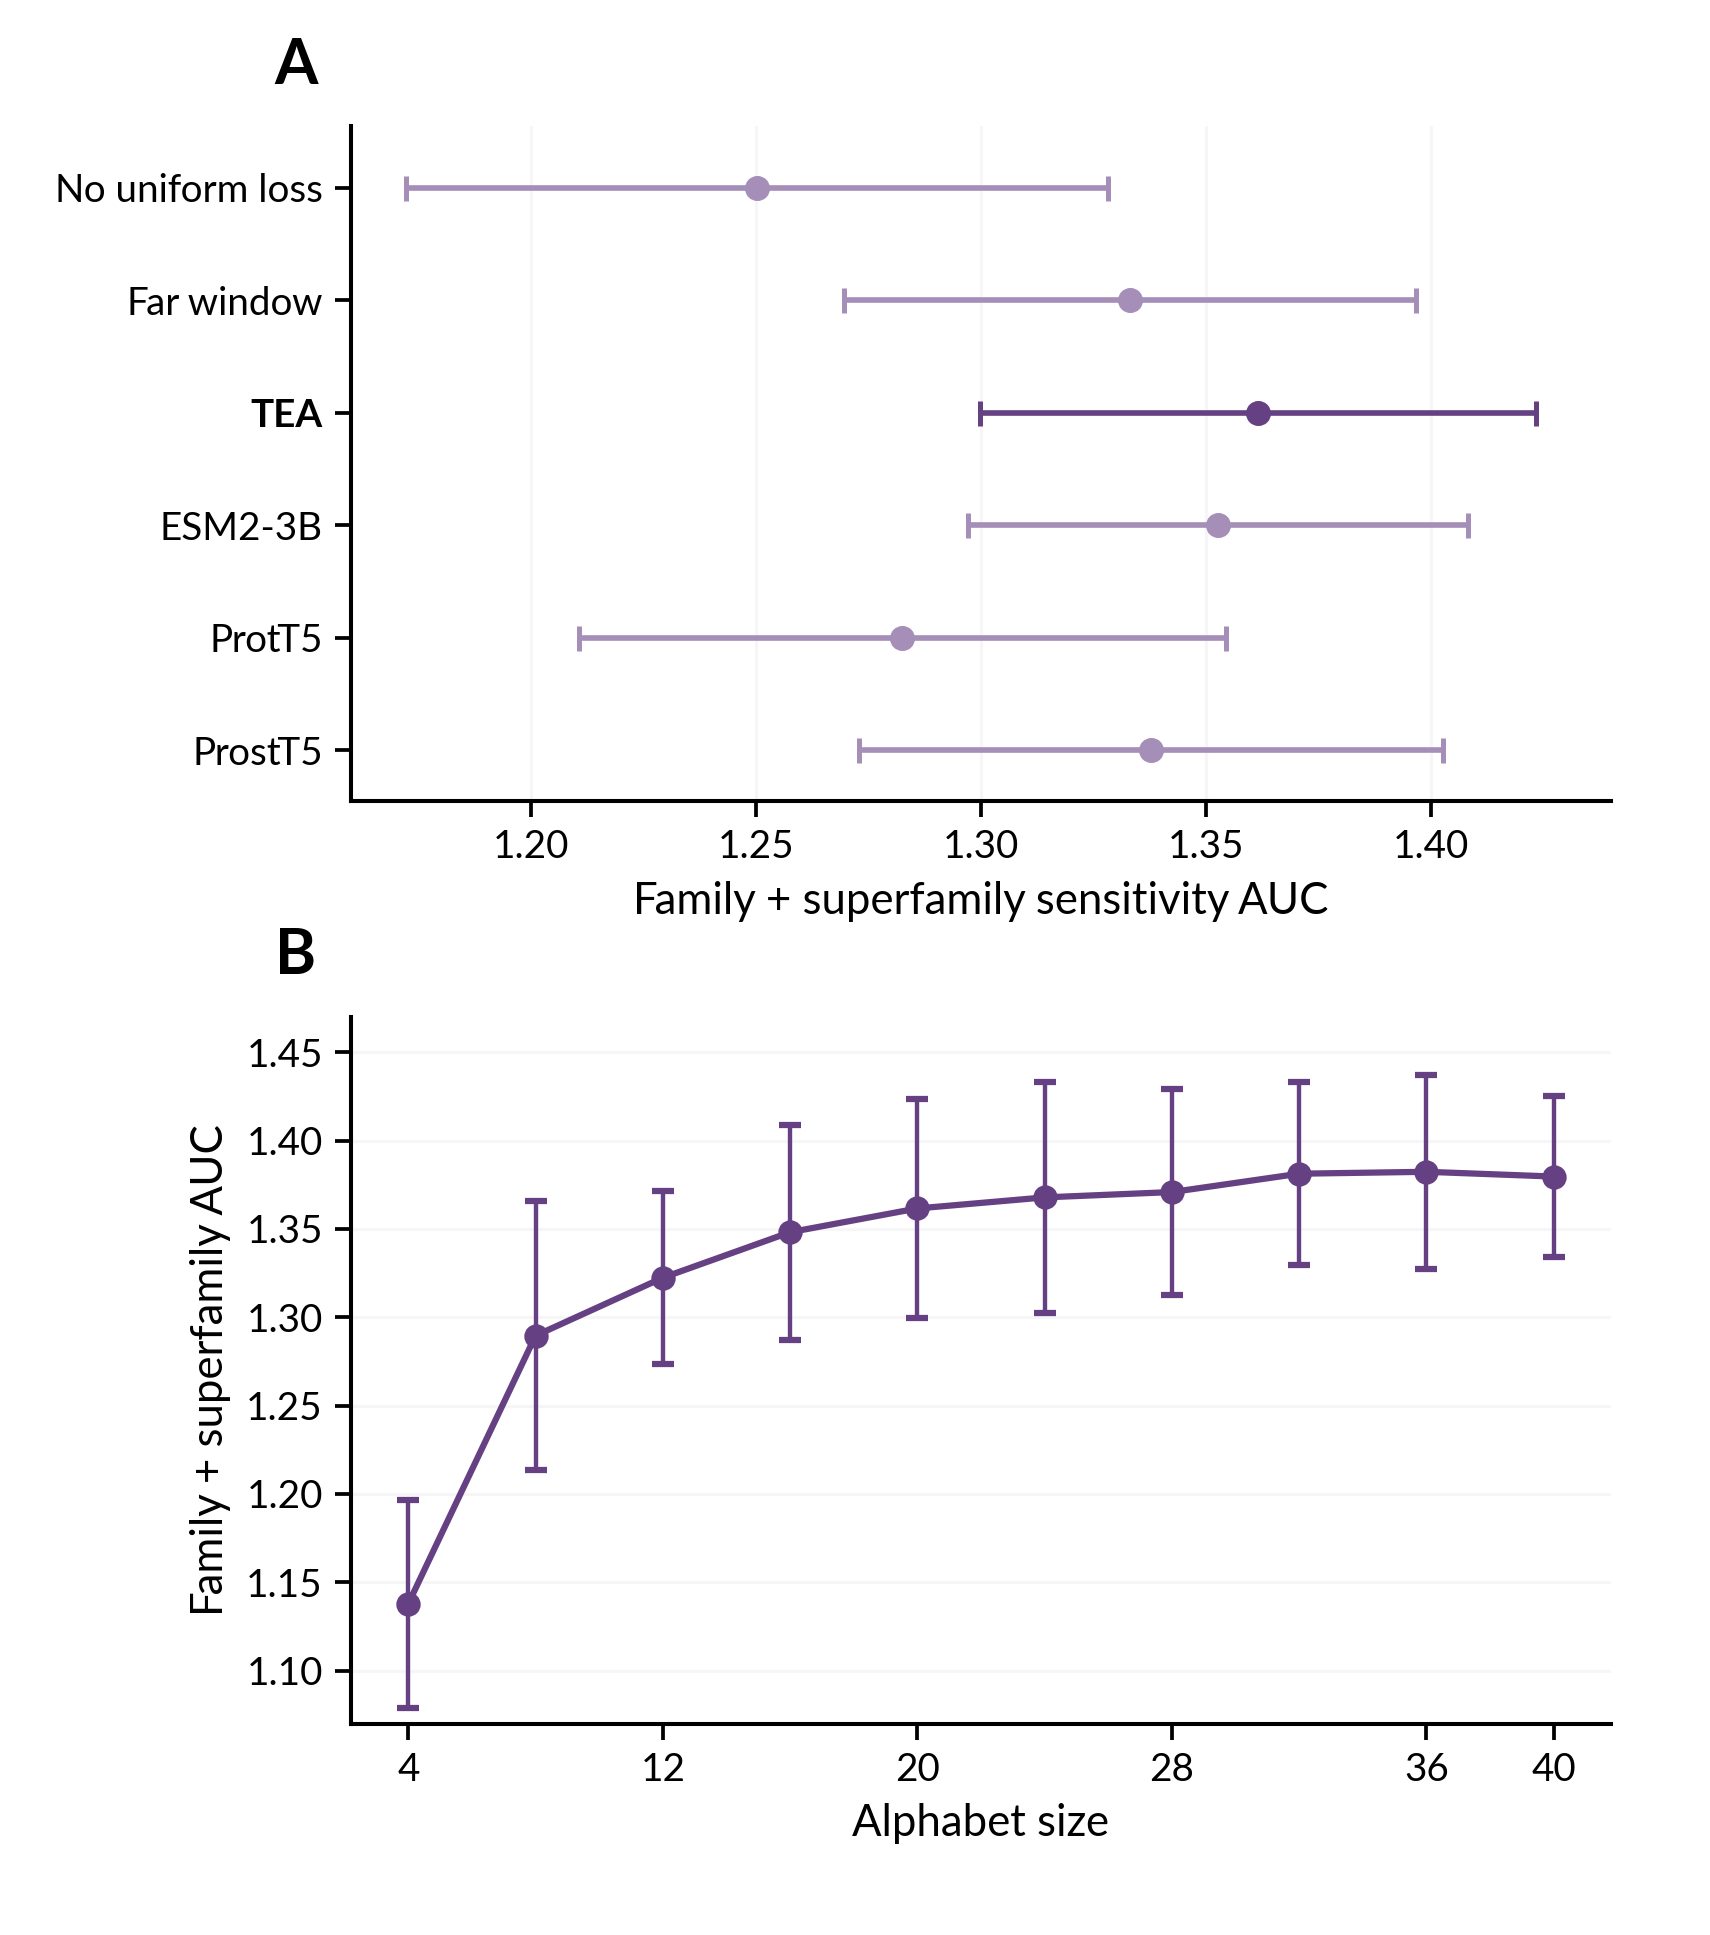

In [2]:
import matplotlib.pyplot as plt
plt.close('all')
plt.rcdefaults()


from io import BytesIO
from IPython.display import display, Image as InlineImage
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib as mpl

ROOT = Path('..').resolve()  # Run from notebooks.
DATA = ROOT / 'data'

# Physical paper dimensions, in inches; typography is specified at this size.
PAPER_STYLE = {'font': 'Lato', 'font_size': 7.0, 'tick_size': 6.5,
               'legend_size': 6.3, 'panel_size': 10.0, 'dpi': 450,
               'line_width': 1.05, 'marker_size': 2.8}

def paper_rc():
    mpl.rcParams.update({
        'font.family': PAPER_STYLE['font'], 'font.size': PAPER_STYLE['font_size'],
        'font.weight': 'normal', 'axes.labelweight': 'normal',
        'axes.labelsize': PAPER_STYLE['font_size'], 'axes.labelpad': 2.5,
        'xtick.labelsize': PAPER_STYLE['tick_size'],
        'ytick.labelsize': PAPER_STYLE['tick_size'],
        'legend.fontsize': PAPER_STYLE['legend_size'], 'legend.frameon': False,
        'legend.handlelength': 1.5, 'legend.labelspacing': .35,
        'axes.spines.top': False, 'axes.spines.right': False,
        'axes.linewidth': .65, 'xtick.major.size': 2.5, 'ytick.major.size': 2.5,
        'xtick.major.width': .6, 'ytick.major.width': .6,
        'xtick.major.pad': 2, 'ytick.major.pad': 2,
        'grid.linewidth': .45, 'grid.color': '#dedde1',
        'mathtext.fontset': 'custom', 'mathtext.rm': 'Lato',
        'mathtext.it': 'Lato:italic', 'mathtext.bf': 'Lato:bold',
        'mathtext.cal': 'Lato', 'mathtext.sf': 'Lato', 'mathtext.tt': 'Lato',
        'path.simplify': False, 'savefig.bbox': None,
    })

def paper_axis(axis):
    clean_panel(axis)
    axis.xaxis.label.set_size(PAPER_STYLE['font_size'])
    axis.yaxis.label.set_size(PAPER_STYLE['font_size'])
    axis.tick_params(labelsize=PAPER_STYLE['tick_size'], width=.6, length=2.5)
    for spine in axis.spines.values():
        spine.set_linewidth(.65)

def paper_letter(figure, axis, letter, *, dx=-.20, dy=.07):
    # Offsets are physical inches, independent of the subplot aspect ratio.
    bounds = axis.get_position(original=True)
    width, height = figure.get_size_inches()
    return figure.text(bounds.x0 + dx/width, bounds.y1 + dy/height, letter,
                       ha='left', va='bottom', fontsize=PAPER_STYLE['panel_size'],
                       fontweight='bold')

def physical_axes(figure, rectangle):
    width, height = figure.get_size_inches()
    x, y, w, h = rectangle
    return figure.add_axes([x/width, y/height, w/width, h/height])

def clean_panel(axis):
    for location in ('left','center','right'):
        axis.set_title('', loc=location)
    for artist in list(axis.texts):
        if artist.get_text().strip() in 'ABCDEF' and len(artist.get_text().strip()) == 1:
            artist.remove()


paper_rc()
SOURCE = DATA/'plot_tables/ablations/summary_sensitivity_sum.tsv'
frame = pd.read_csv(SOURCE, sep='\t')
for row in frame.itertuples():
    folds = np.array([getattr(row, f'fold_{i}') for i in range(4)], dtype=float)
    center = folds.mean()
    half = 1.96 * folds.std(ddof=0) / np.sqrt(4)

COLORS = {'selected':'#654183', 'other':'#a58fb8',
          'short':'#3E88B7', 'medium':'#654183',
          'long':'#df951e', 'full':'#39836b'}
SIZE = (3.8, 4.3)  # physical paper inches
LAYOUT = {
    'A':(.78,2.52,2.80,1.50),
    'B':(.78,.47,2.80,1.57),
}
fig = plt.figure(figsize=SIZE)
axes = {key:physical_axes(fig,rect) for key,rect in LAYOUT.items()}

def value(panel,condition):
    result = frame.loc[frame.panel.eq(panel) & frame.condition.eq(condition)]
    return result.iloc[0]

def horizontal(axis,items):
    positions = np.arange(len(items))
    for position,(panel,condition,label) in enumerate(items):
        row = value(panel,condition)
        color = COLORS['selected'] if condition == 'selected_recipe' else COLORS['other']
        axis.errorbar(row['mean'],position,
                      xerr=[[row['mean']-row['lower']],
                            [row['upper']-row['mean']]],
                      fmt='o',color=color,markersize=3.0,
                      elinewidth=.9,capsize=2.0,capthick=.8,zorder=3)
    axis.set_yticks(positions,[label for _,_,label in items])
    axis.set_ylim(len(items)-.55,-.55)
    axis.set_xlabel('Family + superfamily sensitivity AUC')
    axis.grid(axis='x',alpha=.25,lw=.5)
    axis.set_axisbelow(True)

core = [
    ('core','kl_0','No uniform loss'),
    ('core','window_6_10','Far window'),
    ('core','selected_recipe','TEA'),
    ('plm','esm2-3b','ESM2-3B'),
    ('plm','prott5','ProtT5'),
    ('plm','prostt5','ProstT5'),
]
horizontal(axes['A'],core)
for label in axes['A'].get_yticklabels():
    if label.get_text() == 'TEA':
        label.set_fontweight('bold')

sizes = [4,8,12,16,20,24,28,32,36,40]
rows = [value('alphabet','selected_recipe' if size == 20
              else f'k{size:02d}_window_1_5') for size in sizes]
means = np.array([row['mean'] for row in rows])
lower = means-np.array([row['lower'] for row in rows])
upper = np.array([row['upper'] for row in rows])-means
axes['B'].plot(sizes,means,color=COLORS['selected'],marker='o',
               markersize=2.9,lw=1.0)
axes['B'].errorbar(sizes,means,yerr=[lower,upper],fmt='none',
                   capsize=1.7,elinewidth=.7,color=COLORS['selected'])
axes['B'].set(xlabel='Alphabet size',ylabel='Family + superfamily AUC')
axes['B'].set_xticks([4,12,20,28,36,40])
axes['B'].grid(axis='y',alpha=.25,lw=.5)

axes['A'].set_xlim(1.16,1.44)
axes['B'].set_ylim(1.07,1.47)
for axis in axes.values():
    paper_axis(axis)
    axis.tick_params(labelsize=6.2)
for letter,axis in axes.items():
    paper_letter(fig,axis,letter,dx=-.17,dy=.07)
with BytesIO() as image_buffer:
    fig.savefig(image_buffer, format='png', dpi=PAPER_STYLE['dpi'],facecolor='white')
    plt.close(fig)
    display(InlineImage(data=image_buffer.getvalue()))

## Domain examples

In [3]:
plt.close('all')
plt.rcdefaults()



from matplotlib.colors import to_rgba
from matplotlib.patches import Rectangle
from PIL import Image

import portein
from biotite.sequence import ProteinSequence
from biotite.sequence.align import Alignment
from biotite.sequence.graphics import SymbolPlotter, get_color_scheme, plot_alignment
from portein.plot.secondary_structure import get_ss_elements, make_patch

ROOT = next(base for base in (Path.cwd(), *Path.cwd().parents)
            if (base / 'data/fasta/scope40_2_08').is_dir())
DATA = ROOT / 'data/plot_tables/model/domain_examples'
ASSETS = ROOT / 'data/assets/domain_examples'

tea_palette = pd.read_csv(DATA / 'tea_colors.tsv', sep='\t')
i3d_palette = pd.read_csv(DATA / '3di_colors.tsv', sep='\t')
TEA_COLORS = dict(zip(tea_palette.letter, tea_palette.color))
I3D_COLORS = dict(zip(i3d_palette.letter, i3d_palette.color))
alphabet = ProteinSequence('A').get_alphabet()
AA_COLORS = dict(zip(alphabet, get_color_scheme('clustalx', alphabet)))


STYLE = {
    'font': 'Lato',
    'symbol_size': 6.5,
    'label_size': 7,
    'panel_size': 8,
    'block_spacing': .65,
    'box_alpha': .28,
    'aa_outline_width': .55,
    'strand_head_length': 1.,  # Maximum arrowhead length in residue cells.
    'width_ratios': (4.5, 1),
    'row_spacing': .30,
    'column_spacing': .12,
    'dpi': 450,
}

HELIX_STYLE = portein.HelixConfig(
    wave_arc_width=.8, wave_arc_height=.55, wave_arc_length=.5, color='#526170')
STRAND_STYLE = portein.SheetConfig(
    head_height=.40, tail_height=.20, outline_width=.25,
    color='#526170', outline_color='#526170')
COIL_STYLE = portein.TurnConfig(
    height=.16, circle_radius=0, arc_width=.65,
    arc_color='#a2abb3', circle_color='#a2abb3', opacity=1.)

### Structure images and residue encodings

In [4]:
def render_cartoon(entry):
    return ASSETS / f"{entry['domain']}_pymol.png"


class EncodingPlotter(SymbolPlotter):
    def __init__(self, ax, encodings):
        super().__init__(ax)
        self.encodings = encodings

    def plot_symbol(self, bbox, alignment, column_i, seq_i):
        if seq_i == len(self.encodings) - 1:
            return  # Portein draws the shared DSSP trace after the letters.
        letter = str(alignment.sequences[seq_i][alignment.trace[column_i, seq_i]])
        name = self.encodings[seq_i][0]
        palette = AA_COLORS if name == 'aa' else TEA_COLORS if name == 'tea' else I3D_COLORS
        color = palette.get(letter, '#999999')
        self.axes.add_patch(Rectangle(
            (bbox.x0 + .025, bbox.y0 + .07), .95, .86,
            facecolor='white' if seq_i == 0 else to_rgba(color, STYLE['box_alpha']),
            edgecolor=color if seq_i == 0 else 'none',
            linewidth=STYLE['aa_outline_width'],
        ))
        self.axes.text(
            bbox.x0 + .5, bbox.y0 + .5, letter if name in ('aa', 'tea') else letter.lower(),
            ha='center', va='center', color='#20252a',
            fontsize=STYLE['symbol_size'], fontfamily=STYLE['font'],
            fontstyle='italic' if seq_i == 1 else 'normal', clip_on=True,
        )


def plot_encodings(ax, entry, encodings, symbols_per_line):
    sequences = [ProteinSequence(entry[name]) for name, _ in encodings]
    row_count = len(encodings)
    trace = np.repeat(np.arange(entry['length'])[:, None], row_count, axis=1)
    alignment = Alignment(sequences, trace)
    plot_alignment(
        ax, alignment, EncodingPlotter(ax, encodings),
        symbols_per_line=symbols_per_line, labels=[label for _, label in encodings],
        label_size=STYLE['label_size'], spacing=STYLE['block_spacing'],
        show_numbers=False,
    )
    # Label the shared end position on the amino-acid row.
    blocks = int(np.ceil(entry['length'] / symbols_per_line))
    ax.text(entry['length'] + .6, .5, str(entry['length']),
            fontsize=5.5, ha='left', va='center', clip_on=False)
    elements = get_ss_elements(entry['dssp'])
    # Portein's final span uses an inclusive end; convert it to a cell boundary.
    elements[-1] = (elements[-1][0], elements[-1][1], entry['length'])
    for block in range(blocks):
        start = block * symbols_per_line
        stop = min(start + symbols_per_line, entry['length'])
        y = block * (row_count + STYLE['block_spacing']) + row_count - .5
        for state, left, right in elements:
            if right <= start or left >= stop:
                continue
            # Draw whole secondary structure elements and clip them at row wraps.
            for patch in make_patch('HW' if state == 'H' else state,
                                    left - start, y, right - start, y, ax,
                                    HELIX_STYLE, STRAND_STYLE, COIL_STYLE):
                if state == 'E':
                    # Portein defaults to a head one quarter of the strand long.
                    patch.set_data(head_length=min(STYLE['strand_head_length'], (right - left) / 4))
                ax.add_patch(patch)
    for label in ax.get_yticklabels():
        if label.get_text() == 'TEA':
            label.set_fontstyle('italic')
    ax.text(0, 1.08, f"{entry['domain']}  ({entry['scop']})  ·  {entry['class_name']}",
            transform=ax.transAxes, fontsize=STYLE['label_size'], va='bottom')

### Alphabet palette and layout

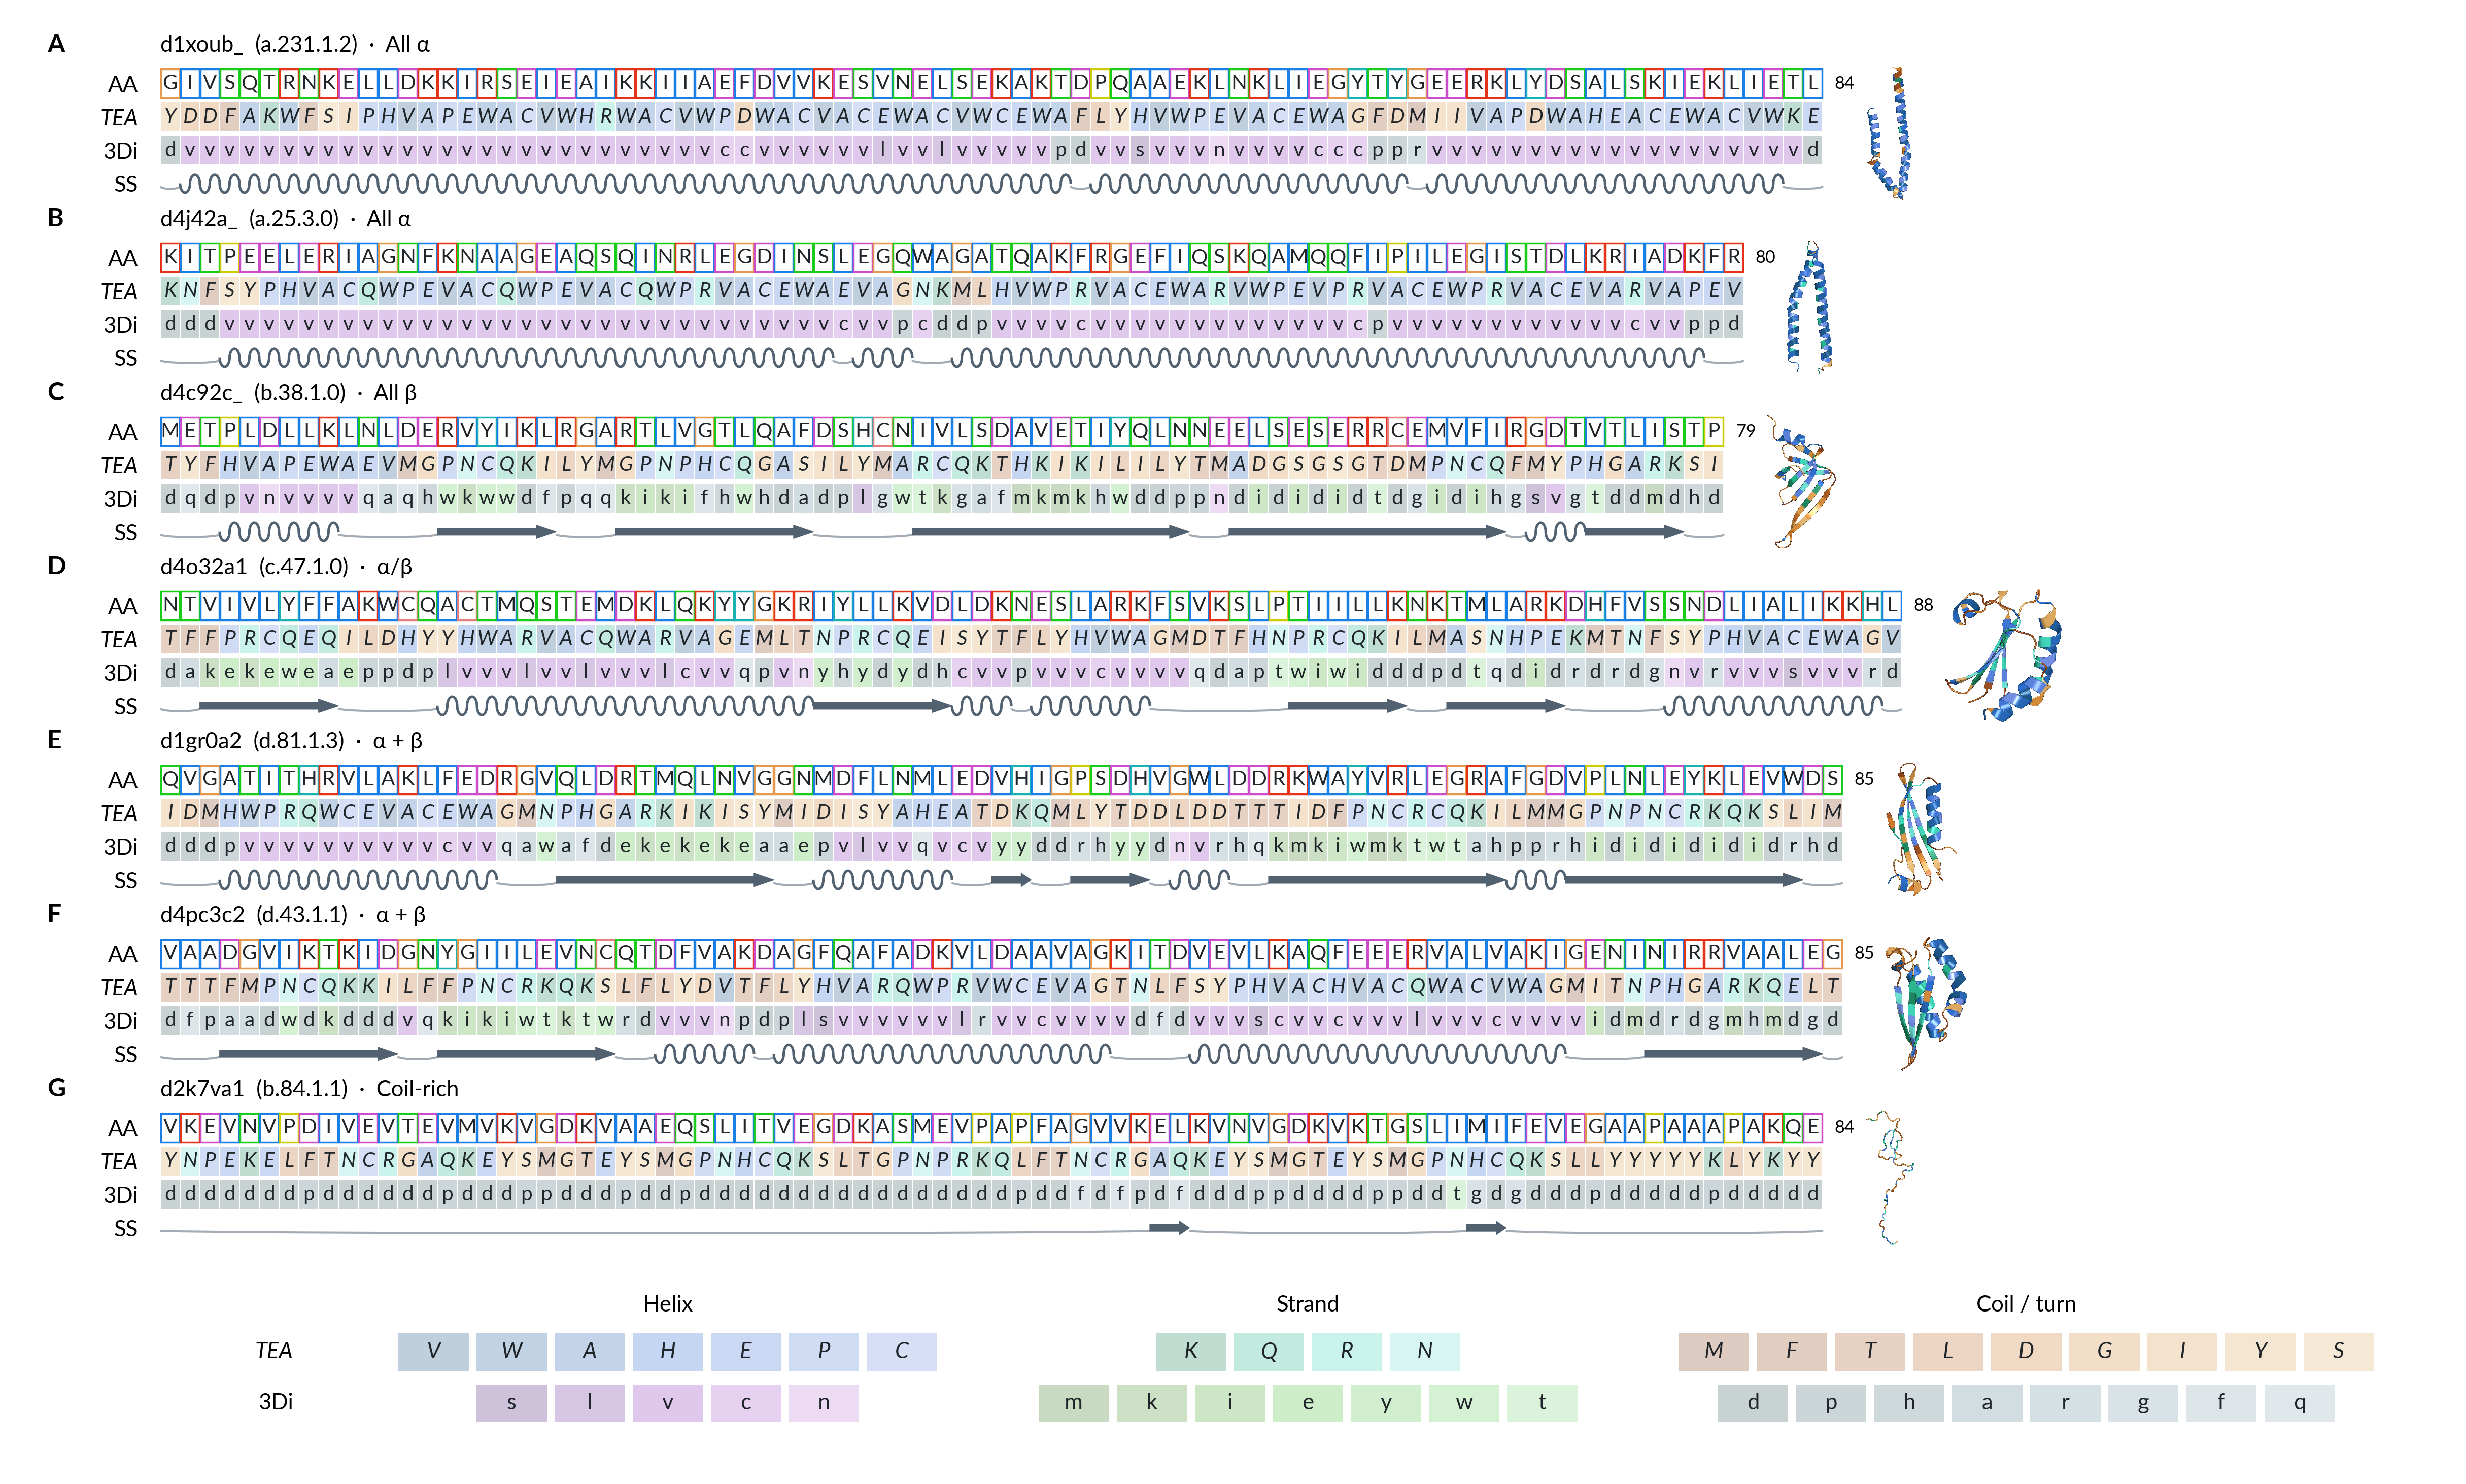

In [5]:
def plot_palette_legend(ax):
    palettes = [(tea_palette, TEA_COLORS, 1.8, True),
                (i3d_palette, I3D_COLORS, .65, False)]
    cursor = 0
    for group, label in [('helix', 'Helix'), ('strand', 'Strand'), ('coil', 'Coil / turn')]:
        members = [frame.loc[frame.group.eq(group)].sort_values(
            ['preference_fraction', 'letter'], ascending=[False, True]).letter.tolist()
            for frame, _, _, _ in palettes]
        width = max(map(len, members))
        ax.text(cursor + width / 2, 2.85, label, ha='center', va='center', fontsize=7)
        for letters, (_, colors, y, italic) in zip(members, palettes):
            offset = cursor + (width - len(letters)) / 2
            for i, letter in enumerate(letters):
                ax.add_patch(Rectangle((offset + i + .05, y - .42), .9, .84,
                                       facecolor=to_rgba(colors[letter], STYLE['box_alpha']),
                                       edgecolor='none'))
                ax.text(offset + i + .5, y, letter if italic else letter.lower(),
                        ha='center', va='center', fontsize=7,
                        fontstyle='italic' if italic else 'normal', color='#20252a')
        cursor += width + 1.2
    ax.text(-1.3, 1.8, 'TEA', va='center', ha='right', fontstyle='italic', fontsize=7)
    ax.text(-1.3, .65, '3Di', va='center', ha='right', fontsize=7)
    ax.set(xlim=(-3, cursor - .7), ylim=(0, 3.3))
    ax.set_axis_off()


def show_domain_examples(with_prostt5=False):
    plt.rcdefaults()
    plt.rcParams.update({'font.family': STYLE['font'], 'font.size': STYLE['label_size']})
    filename = 'examples_with_prostt5.tsv' if with_prostt5 else 'examples.tsv'
    examples = pd.read_csv(DATA / filename, sep='\t')
    lengths = examples.length
    symbols_per_line = int(lengths.max())
    encodings = [('aa', 'AA'), ('tea', 'TEA'), ('3di', '3Di')]
    if with_prostt5:
        encodings.append(('prostt5_3di', 'ProstT5'))
    encodings.append(('dssp', 'SS'))
    figure_height = 7.2 if with_prostt5 else 6.5
    left_margin = .085 if with_prostt5 else .065
    figure = plt.figure(figsize=(10.8, figure_height), facecolor='white')
    blocks = np.ceil(lengths / symbols_per_line).astype(int)
    row_heights = (len(encodings) * blocks + STYLE['block_spacing'] * (blocks - 1)).tolist()
    layout = figure.add_gridspec(
        len(examples) + 1, 2,
        height_ratios=row_heights + [4.4],
        width_ratios=STYLE['width_ratios'],
        hspace=STYLE['row_spacing'], wspace=STYLE['column_spacing'],
        left=left_margin, right=.98, bottom=.035, top=.955,
    )
    for i, entry in enumerate(examples.to_dict('records')):
        ax = figure.add_subplot(layout[i, 0])
        plot_encodings(ax, entry, encodings, symbols_per_line)
        ax.text(-.065, 1.08, chr(ord('A') + i), transform=ax.transAxes,
                fontsize=STYLE['panel_size'], fontweight='bold', va='bottom')
        # Place each cartoon immediately after its last residue.
        bounds = ax.get_position()
        edge = figure.transFigure.inverted().transform(
            ax.transData.transform((entry['length'], 0)))[0]
        width = figure.get_figwidth()
        cartoon_ax = figure.add_axes([edge + .19/width, bounds.y0,
                                     1.05/width, bounds.height])
        cartoon_ax.set_anchor('W')
        with Image.open(render_cartoon(entry)) as image:
            image = image.convert('RGBA')
            bounds = image.getchannel('A').getbbox()
            cartoon_ax.imshow(np.asarray(image.crop(bounds)), interpolation='none', aspect='equal')
        cartoon_ax.set_axis_off()
    plot_palette_legend(figure.add_subplot(layout[-1, :]))
    with BytesIO() as image_buffer:
        figure.savefig(image_buffer, format='png', dpi=STYLE['dpi'], facecolor='white')
        plt.close(figure)
        display(InlineImage(data=image_buffer.getvalue()))

show_domain_examples()

## Domain examples with ProstT5

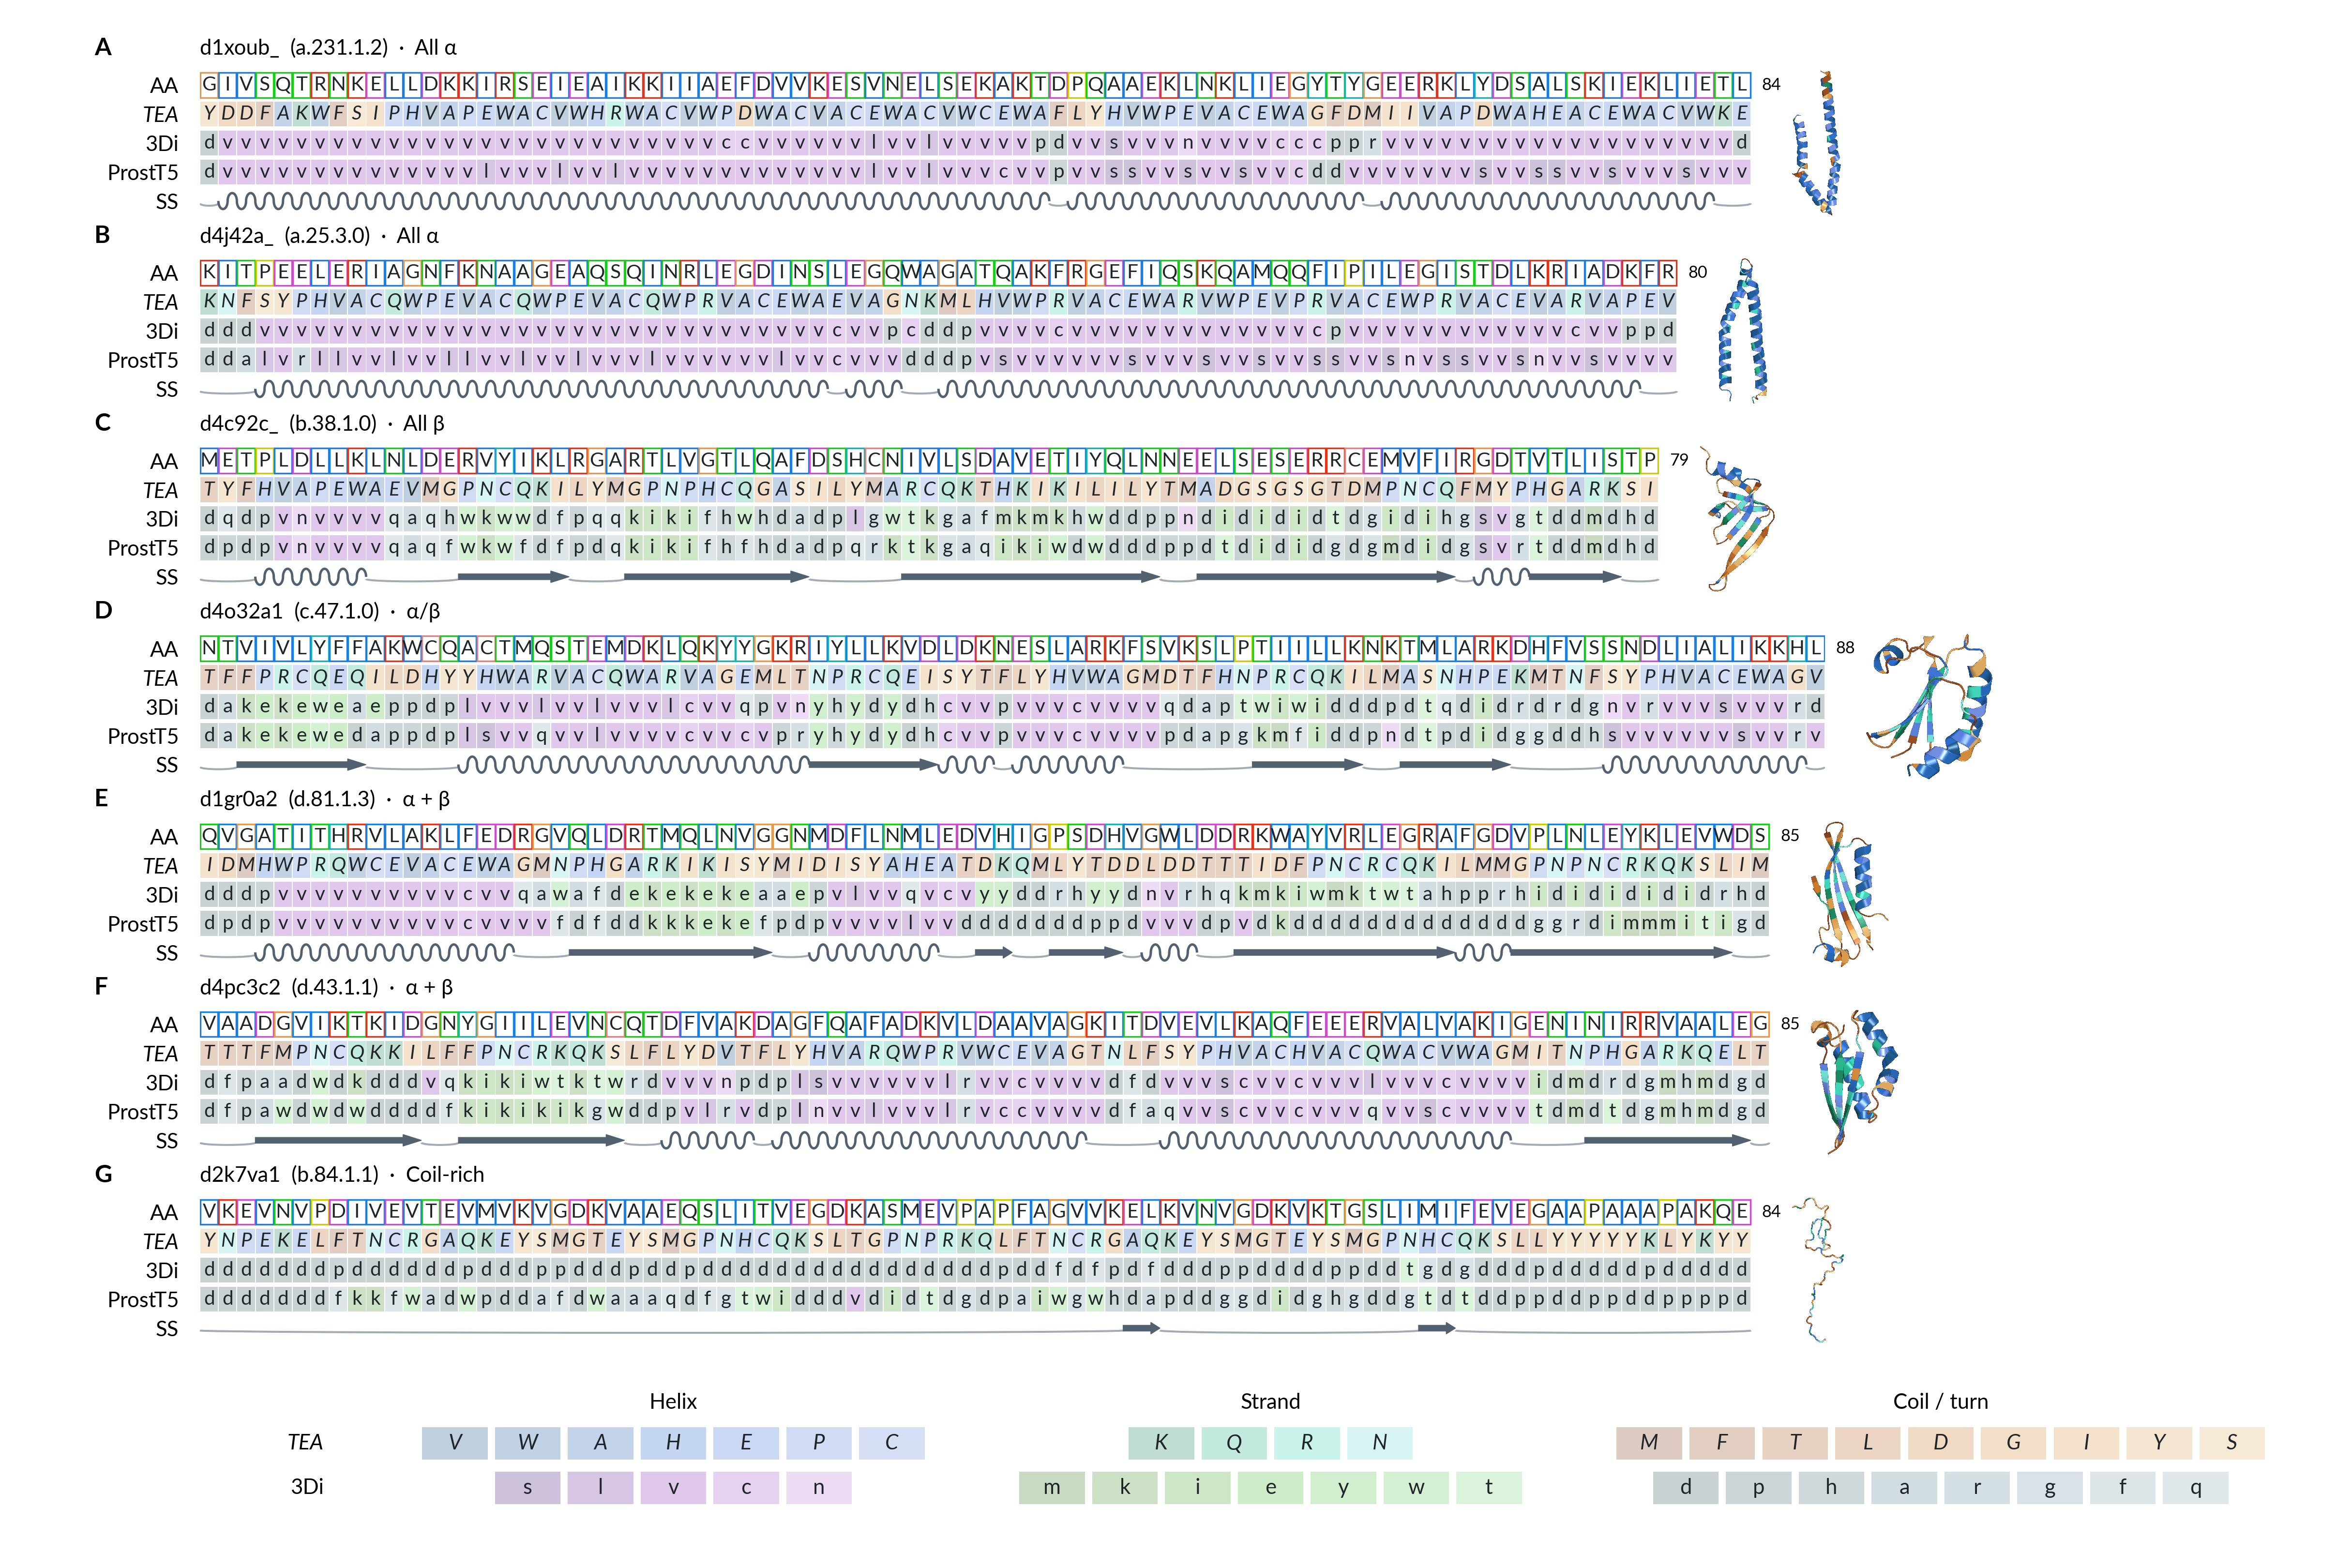

In [6]:
show_domain_examples(with_prostt5=True)

## Evalue fit transfer

In [7]:
plt.close('all')
plt.rcdefaults()


import json

ROOT = Path('..').resolve()  # Run from notebooks.
DATA = ROOT / 'data'


# Physical paper dimensions, in inches; typography is specified at this size.
PAPER_STYLE = {'font': 'Lato', 'font_size': 7.0, 'tick_size': 6.5,
               'legend_size': 6.3, 'panel_size': 10.0, 'dpi': 450,
               'line_width': 1.05, 'marker_size': 2.8}







STEAM = "#664082"

TEA = "#9a70b8"

LIGHT_GRAY = "#aaa4ac"

def read_json(path: Path):
    with path.open() as handle:
        return json.load(handle)

def matched_log_calibration_limits(*arrays, lower=1e-3):
    """Return common decade limits for expected-versus-observed panels."""
    positive = np.concatenate([
        np.asarray(values, dtype=float).ravel()
        for values in arrays
    ])
    positive = positive[np.isfinite(positive) & (positive > 0)]
    upper = 10.0 ** np.ceil(np.log10(max(float(positive.max()), lower * 10)))
    return lower, upper

def plot_loglinear_fit(axis, fit_path):
    calibration = read_json(
        fit_path
    )
    scores = np.asarray(calibration["scores"], dtype=float)
    observed = np.asarray(calibration["observed_errors_per_query"], dtype=float)
    effective_target_count = float(calibration["effective_target_count"])
    low, high = calibration["fit_errors_per_query_range"]
    fit = (observed >= low) & (observed <= high)
    m_low = float(calibration["loglinear_m_low"])
    m_high = float(calibration["loglinear_m_high"])
    c = float(calibration["loglinear_c"])
    breakpoint = float(calibration["loglinear_breakpoint"])
    fit_scores = np.linspace(
        float(scores.min()), float(scores.max()), 1500,
    )
    exponent = c + m_low * fit_scores + (m_high - m_low) * np.maximum(
        0.0, fit_scores - breakpoint
    )
    fitted = effective_target_count * np.power(10.0, exponent)

    axis.scatter(
        scores[~fit], observed[~fit], s=13, color=LIGHT_GRAY, alpha=0.65,
        edgecolors="none", label="Empirical thresholds outside fit range",
    )
    axis.scatter(
        scores[fit], observed[fit], s=17, color=TEA, alpha=0.82,
        edgecolors="none", label="Empirical thresholds used in fit",
    )
    axis.plot(
        fit_scores, fitted, color=STEAM, linewidth=2.5,
        label="Continuous two-slope fit",
    )
    axis.set_yscale("log")
    axis.set(
        xlabel="Final raw ranking score",
        ylabel="Observed different-superfamily false positives per query",
        title="SCOP40c exhaustive diversity-adjusted E-value fit",
    )
    axis.grid(axis="y", linestyle="--", alpha=0.18)
    axis.legend(frameon=False, fontsize=9, loc="lower left")

### Calibration transfer

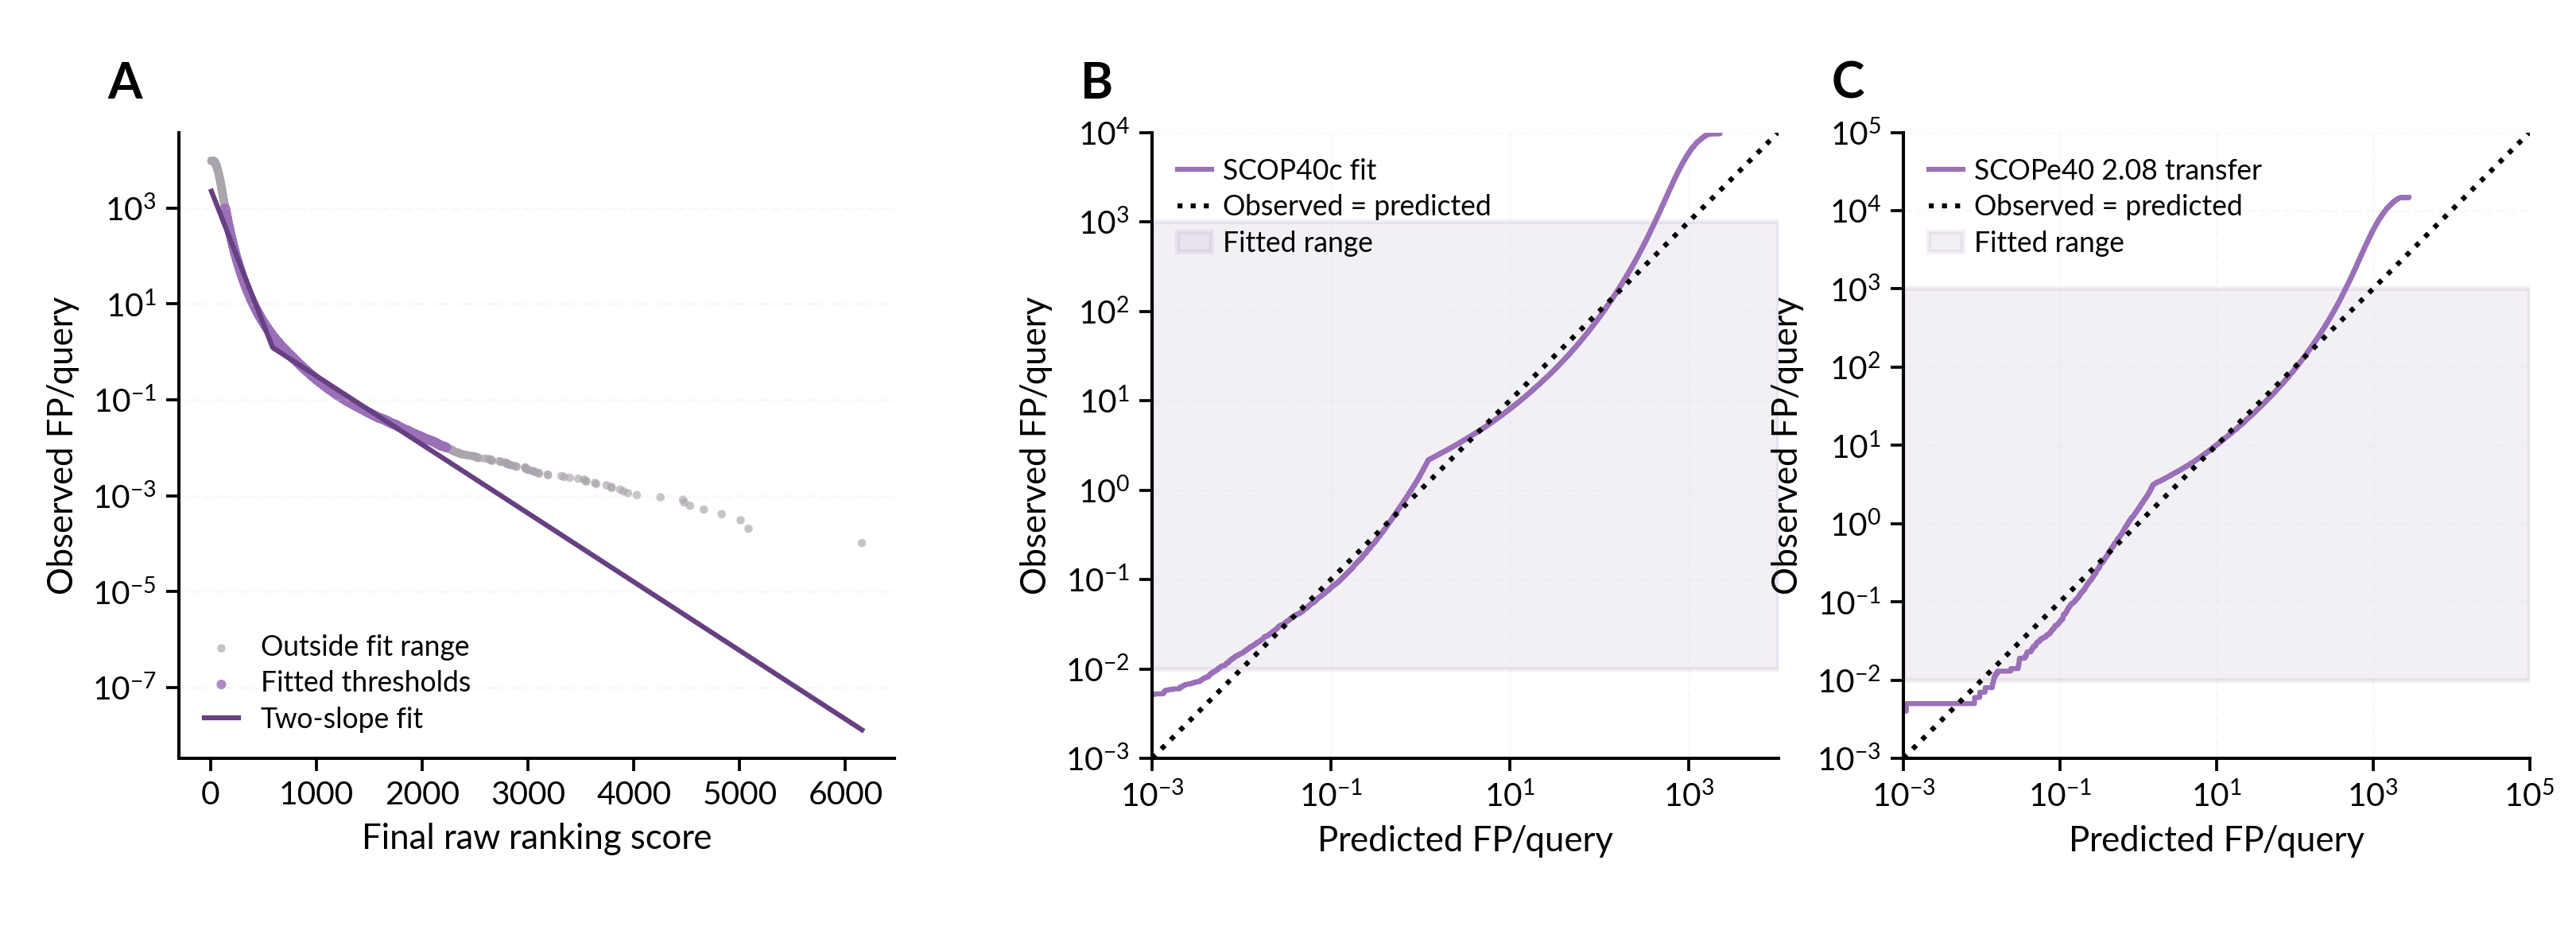

In [8]:
def plot_piecewise_calibration_transfer(axes, fit_path, transfer_path):
    fit = read_json(fit_path)
    transfer = read_json(transfer_path)
    low, high = map(float, fit["fit_errors_per_query_range"])
    for label, result, axis in zip(
        ("SCOP40c fit", "Overlap-free SCOPe40 2.08 transfer"),
        (fit, transfer), axes,
    ):
        predicted = np.asarray(result["predicted_errors_per_query"], dtype=float)
        observed = np.asarray(result["observed_errors_per_query"], dtype=float)
        axis.step(
            predicted, observed, where="post", color=TEA, linewidth=1.8,
            label="Every empirical score threshold",
        )
        bounds = np.asarray(matched_log_calibration_limits(predicted, observed))
        axis.plot(
            bounds, bounds, color="black", linestyle=":", linewidth=1.4,
            label="Observed = predicted",
        )
        # Thresholds were selected by observed errors/query, i.e. the y axis.
        axis.axhspan(
            low, high, color=STEAM, alpha=0.08,
            label="SCOP40c observed fit range",
        )
        axis.set_xscale("log")
        axis.set_yscale("log")
        axis.set_xlim(*bounds)
        axis.set_ylim(*bounds)
        axis.set(
            xlabel="Predicted false positives per query",
            ylabel="Observed different-superfamily false positives per query",
            title=label,
        )
        axis.grid(which="both", linestyle="--", alpha=0.16)
        axis.legend(frameon=False, fontsize=8.3, loc="upper left")


LAYOUT = {'size':(7.2,2.60),
          'A':(.50,.48,2.00,1.75), 'B':(3.22,.48,1.75,1.75),
          'C':(5.32,.48,1.75,1.75)}
ROOT_EVALUE = DATA/'search_results/steam_final/current/calibration'
paper_rc()
fig = plt.figure(figsize=LAYOUT['size'])
A,B,C = [physical_axes(fig,LAYOUT[name]) for name in 'ABC']
plot_loglinear_fit(A, ROOT_EVALUE/'fit_exhaustive.json')
plot_piecewise_calibration_transfer([B,C], ROOT_EVALUE/'fit_exhaustive.json',
                                    ROOT_EVALUE/'transfer_exhaustive.json')
for axis in (A,B,C):
    clean_panel(axis)
    for artist in list(axis.texts):
        if artist.get_bbox_patch() is not None:
            artist.remove()  # Fit coefficients and range remain in the notebook data.
from matplotlib.collections import PathCollection
for axis in (A,B,C):
    paper_axis(axis)
    axis.set_ylabel('Observed FP/query')
    axis.minorticks_off()
    for line in axis.lines:
        line.set_linewidth(1.0)
    for collection in axis.collections:
        if isinstance(collection,PathCollection):
            collection.set_sizes(collection.get_sizes()*.22)
for axis,cohort in ((B,'SCOP40c fit'),(C,'SCOPe40 2.08 transfer')):
    handles,labels = axis.get_legend_handles_labels()
    labels = [cohort,'Observed = predicted','Fitted range']
    axis.legend(handles,labels,frameon=False,fontsize=5.7,loc='upper left',
                handlelength=1.2,handletextpad=.4)
    axis.set_xlabel('Predicted FP/query')
handles,labels = A.get_legend_handles_labels()
A.legend(handles,['Outside fit range','Fitted thresholds','Two-slope fit'],
         frameon=False,fontsize=5.7,loc='lower left',handlelength=1.2)
for axis,letter in ((A,'A'),(B,'B'),(C,'C')):
    paper_letter(fig,axis,letter)
with BytesIO() as image_buffer:
    fig.savefig(image_buffer, format='png', dpi=PAPER_STYLE['dpi'],facecolor='white')
    plt.close(fig)
    display(InlineImage(data=image_buffer.getvalue()))

## Legacy tea alphabet

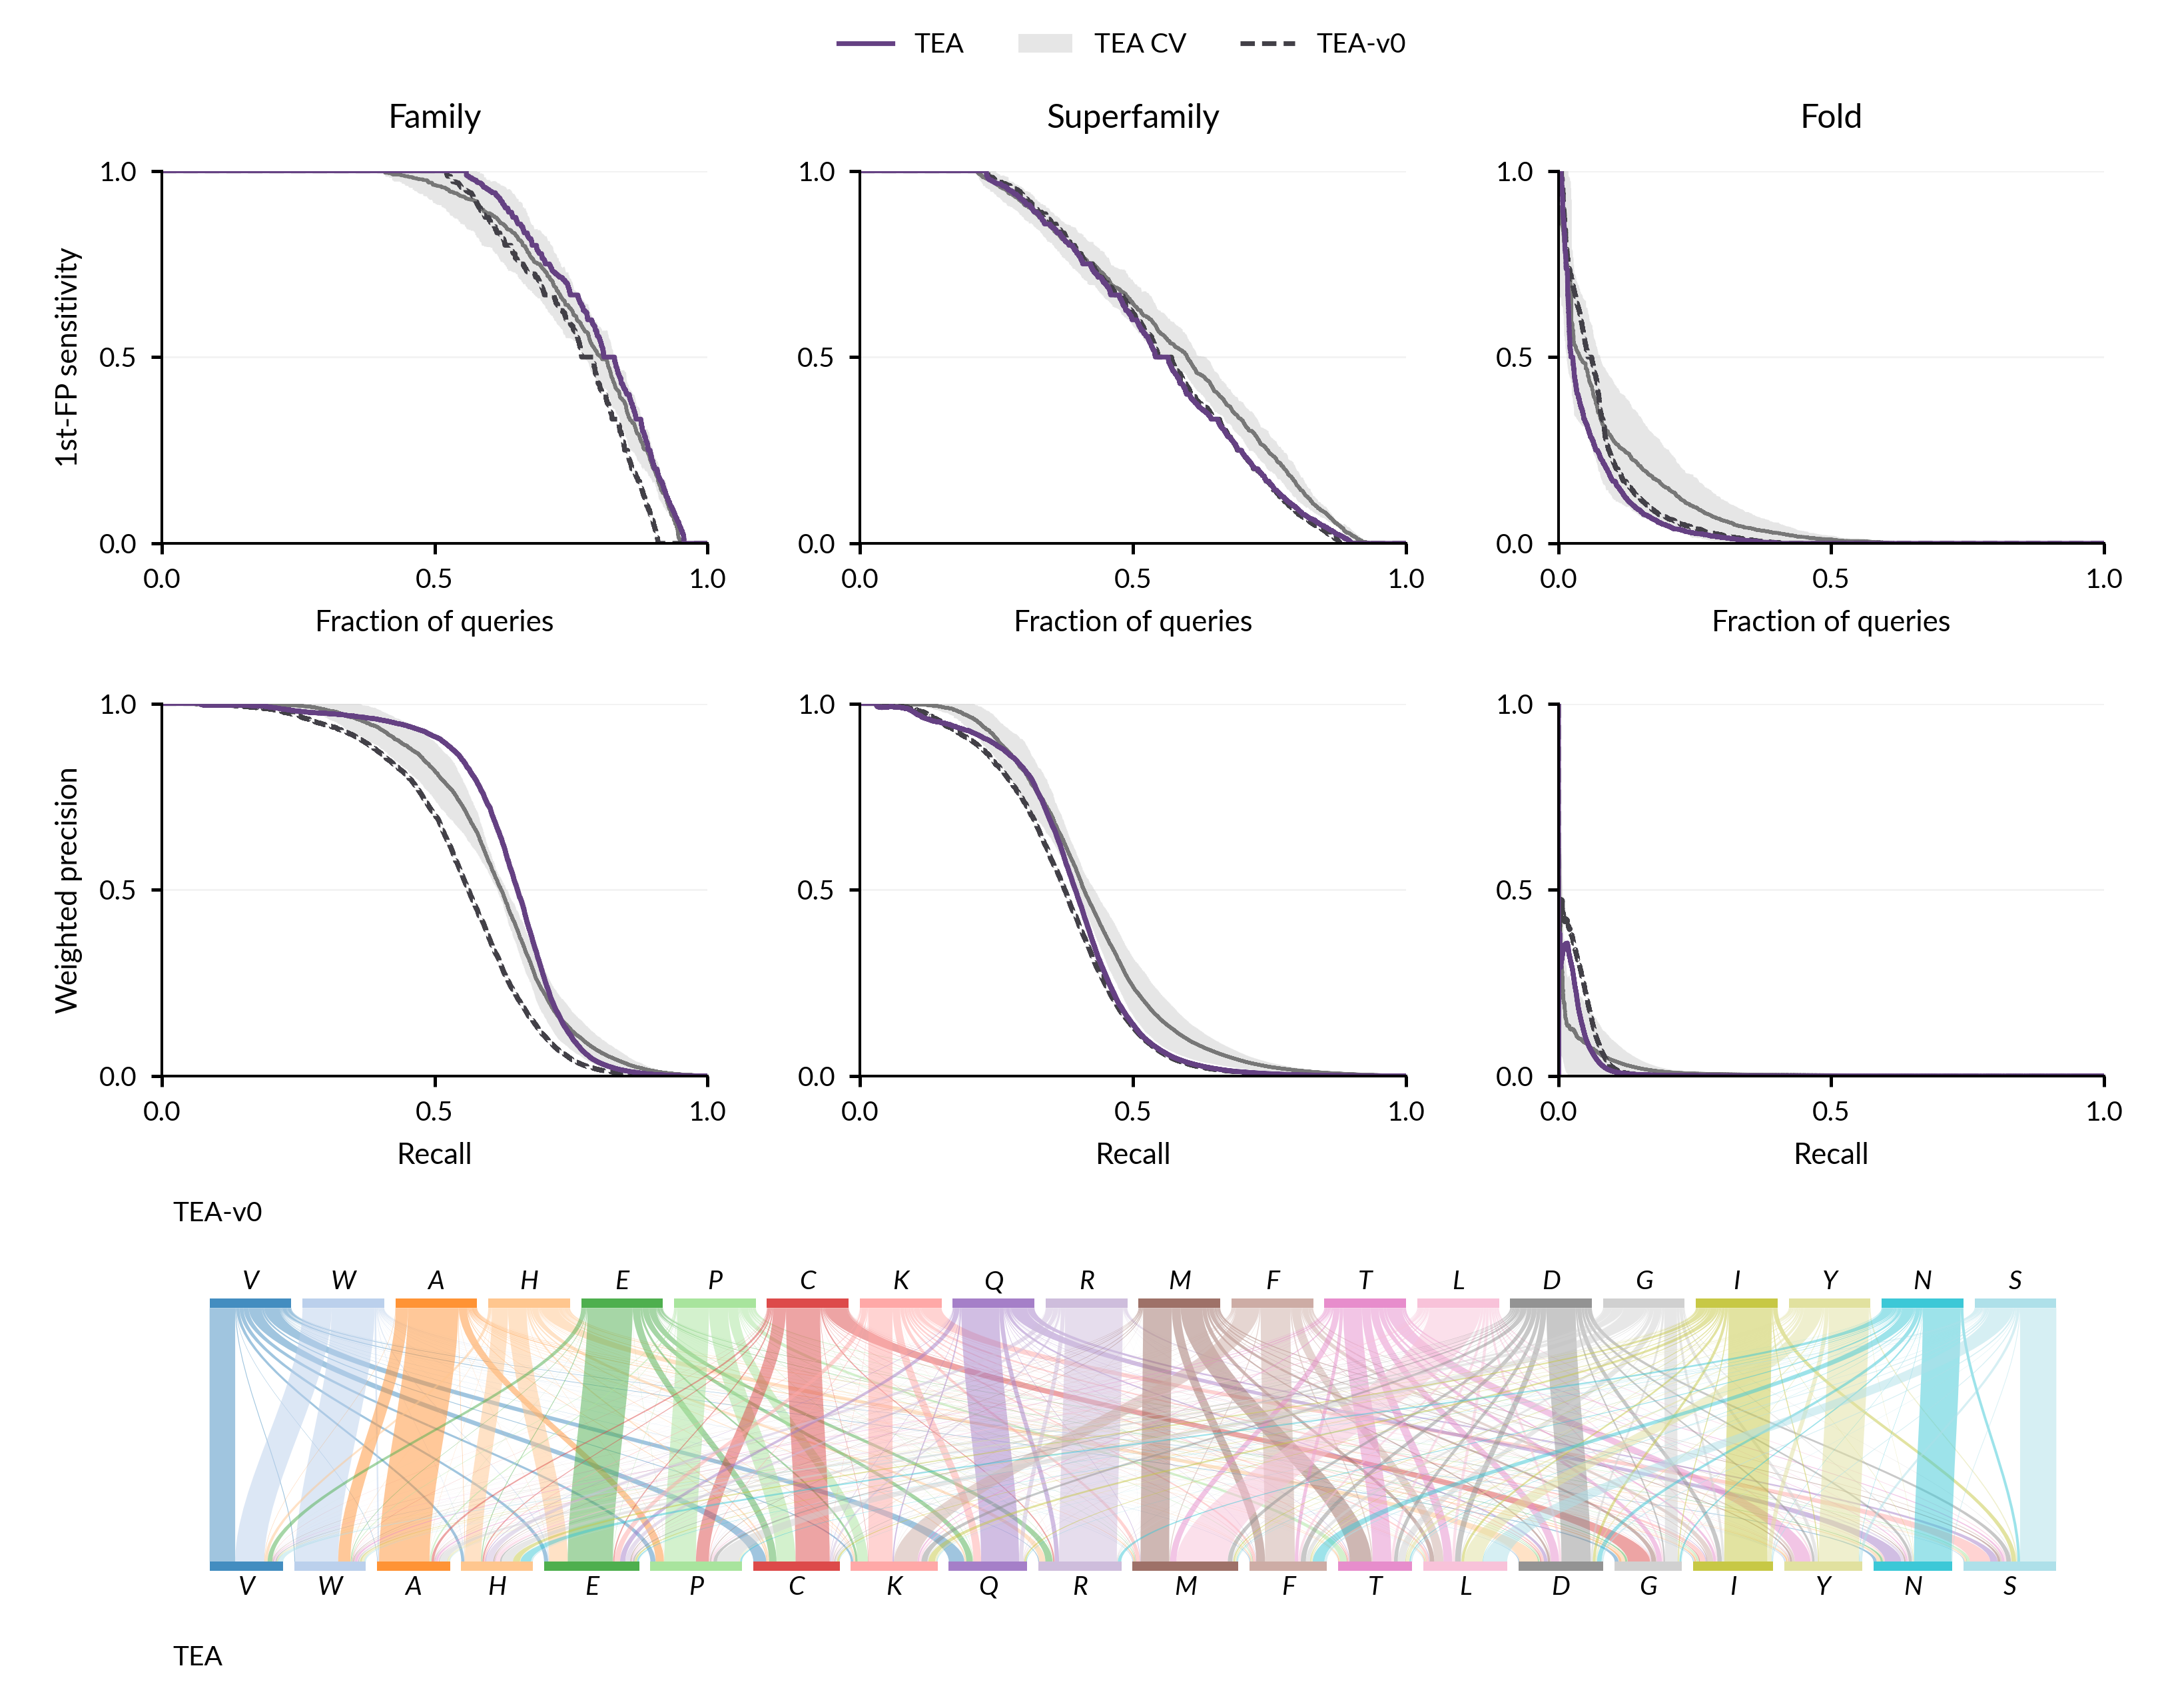

In [9]:
plt.close('all')
plt.rcdefaults()


from matplotlib.lines import Line2D
from matplotlib.patches import Patch, PathPatch
from matplotlib.transforms import Affine2D

ROOT = Path('..').resolve()
DATA = ROOT/'data/plot_tables/scop/alphabet/legacy_comparison'
from sankeyflow import Sankey

STYLE = dict(size=(7.2,5.7),dpi=450,new='#654183',legacy='#424047',cv='#777777')
mpl.rcParams.update({'font.family':'Lato','font.size':7,'font.weight':'normal',
    'axes.labelsize':7,'xtick.labelsize':6.5,'ytick.labelsize':6.5,
    'axes.spines.top':False,'axes.spines.right':False,'axes.linewidth':.65,
    'xtick.major.size':2.5,'ytick.major.size':2.5,'legend.frameon':False,
    'path.simplify':False,'savefig.bbox':None})
fig = plt.figure(figsize=STYLE['size'])
grid = fig.add_gridspec(2,3,left=.075,right=.975,bottom=.37,top=.90,hspace=.43,wspace=.28)
for column,level in enumerate(('family','superfamily','fold')):
    bounds=grid[0,column].get_position(fig)
    fig.text((bounds.x0+bounds.x1)/2,.925,level.capitalize(),ha='center',fontsize=8)
    for row,metric in enumerate(('sensitivity','weighted_pr')):
        ax = fig.add_subplot(grid[row,column])
        cv = pd.read_csv(DATA/f'cv_reference_{level}_{metric}.tsv',sep='\t')
        step = 'post' if metric == 'sensitivity' else 'pre'
        ax.fill_between(cv.x,cv.lower,cv.upper,color=STYLE['cv'],alpha=.18,step=step,linewidth=0)
        ax.step(cv.x,cv['mean'],where=step,color=STYLE['cv'],linewidth=.85)
        for tag,color,dash in (('released_legacy',STYLE['legacy'],(0,(3,1.5))),('new_tea',STYLE['new'],'-')):
            table = pd.read_csv(DATA/f'{tag}_{level}_{metric}.tsv',sep='\t')
            ax.step(table.x,table.y,where=step,color=color,linestyle=dash,linewidth=1.15)
        ax.set(xlim=(0,1),ylim=(0,1),xticks=[0,.5,1],yticks=[0,.5,1],
            xlabel='Fraction of queries' if row == 0 else 'Recall',
            ylabel=('1st-FP sensitivity' if row == 0 else 'Weighted precision') if column == 0 else '')
        ax.grid(axis='y',alpha=.16,linewidth=.45)
fig.legend(handles=[Line2D([],[],color=STYLE['new'],lw=1.15,label='TEA'),
    Patch(facecolor=STYLE['cv'],alpha=.18,label='TEA CV'),
    Line2D([],[],color=STYLE['legacy'],linestyle=(0,(3,1.5)),lw=1.15,label='TEA-v0')],
    loc='upper center',bbox_to_anchor=(.52,.995),ncol=3,fontsize=6.5)

transitions = pd.read_csv(DATA/'legacy_to_new_row_fraction.tsv',sep='\t',index_col=0)
alphabet=list('VWAHEPCKQRMFTLDGIYNS')
transitions=transitions.loc[alphabet,alphabet]
mass=transitions.to_numpy()/len(alphabet)
palette=[tuple(.84*np.asarray(color)+.16) for color in plt.get_cmap('tab20').colors]
nodes=[[(f'old_{c}',.05,dict(label=c,color=palette[i],label_pos='left')) for i,c in enumerate(alphabet)],
    [(f'new_{c}',float(mass[:,i].sum()),dict(label=c,color=palette[i],label_pos='right')) for i,c in enumerate(alphabet)]]
# All transitions use the source-letter color and the same visible opacity.
flows=[(f'old_{a}',f'new_{b}',float(mass[i,j]),
        dict(color=mpl.colors.to_rgba(palette[i],.50)))
    for i,a in enumerate(alphabet) for j,b in enumerate(alphabet) if mass[i,j] > 0]
ax=fig.add_axes([.08,.065,.89,.19])
sankey=Sankey(nodes=nodes,flows=flows,flow_color_mode='',node_width=.035,node_pad_y_min=.006,node_pad_y_max=.006,
    node_opts={'label_format':'{label}','label_pad_x':.018,'label_opts':{'fontsize':6.3,'fontstyle':'italic'}})
sankey.draw(ax=ax)
# Match the horizontal alphabet rows in the main figure Sankeys.
max_x=max(node.x+node.width for level in sankey.nodes for node in level)
transform=Affine2D.from_values(0,-1,-1,0,1,max_x)
for item in [*sankey.flows,*(node for level in sankey.nodes for node in level)]:
    artist=item.artist
    path=transform.transform_path(artist.get_path().transformed(artist.get_patch_transform()))
    replacement=PathPatch(path,facecolor=artist.get_facecolor(),edgecolor=artist.get_edgecolor(),
        linewidth=artist.get_linewidth(),alpha=artist.get_alpha(),zorder=artist.get_zorder())
    artist.remove(); ax.add_patch(replacement); item.artist=replacement
for level_index,level in enumerate(sankey.nodes):
    for node in level:
        node.text.set_position(transform.transform(node.text.get_position()))
        node.text.set(ha='center',va='bottom' if level_index == 0 else 'top',rotation=0)
ax.set(xlim=(-.02,1.02),ylim=(-.10,max_x+.10),aspect='auto',xticks=[],yticks=[])
ax.set_axis_off()
fig.canvas.draw()
renderer=fig.canvas.get_renderer()
for level_index,level in enumerate(sankey.nodes):
    ends=[]
    for text in sorted((node.text for node in level),key=lambda text:text.get_window_extent(renderer).x0):
        box=text.get_window_extent(renderer)
        lane=next((i for i,end in enumerate(ends) if box.x0 > end+2),len(ends))
        if lane == len(ends): ends.append(box.x1)
        else: ends[lane]=box.x1
        if lane:
            x,y=ax.transData.transform(text.get_position())
            y+=(1 if level_index == 0 else -1)*lane*7*fig.dpi/72
            text.set_position(ax.transData.inverted().transform((x,y)))
fig.text(.08,.285,'TEA-v0',ha='left',fontsize=6.5)
fig.text(.08,.025,'TEA',ha='left',fontsize=6.5)
with BytesIO() as image_buffer:
    fig.savefig(image_buffer, format='png', dpi=STYLE['dpi'],facecolor='white')
    plt.close(fig)
    display(InlineImage(data=image_buffer.getvalue()))

## Motifs

In [10]:
plt.close('all')
plt.rcdefaults()




from biotite.visualize import plot_scaled_text

ROOT = Path('..').resolve()
DATA = ROOT / 'data'
ASSETS = ROOT / 'data/assets/motifs'
MOTIFS = DATA / 'plot_tables/model/motifs'
ASSETS.mkdir(parents=True, exist_ok=True)

selected = pd.read_csv(MOTIFS/'selected_motifs.tsv', sep='\t')
profiles = pd.read_csv(MOTIFS/'profiles.tsv', sep='\t')
representatives = pd.read_csv(MOTIFS/'representative_structures.tsv', sep='\t')
selected[['panel', 'category', 'motif', 'num_sequences',
          'num_families', 'num_superfamilies', 'num_folds']]


STYLE = {
    'font_family': 'Lato',
    'logo_font_family': 'DejaVu Sans Mono',
    'font_size': 7,
    'panel_label_size': 10,
    'motif_size': 6.5,
    'motif_weight': 'normal',
    'figure_size': (7.2, 2.9),
    'dpi': 450,
    'hspace': .22,
    'wspace': .08,
}

plt.rcParams['font.family'] = STYLE['font_family']
plt.rcParams['font.weight'] = 'normal'
plt.rcParams['font.size'] = STYLE['font_size']

AA_SYMBOLS = list('ACDEFGHIKLMNPQRSTVWYX')
DSSP_SYMBOLS = list('HBEGITSC')

AA_COLORS = {
    **{letter: '#607C8A' for letter in 'AVLIM'},
    **{letter: '#8B65A7' for letter in 'FWY'},
    **{letter: '#3F9D8B' for letter in 'STNQ'},
    **{letter: '#487FB5' for letter in 'KRH'},
    **{letter: '#D36F5C' for letter in 'DE'},
    **{letter: '#B59049' for letter in 'CGP'},
    'X': '#929292',
}
DSSP_COLORS = {'H':'#2C78AD','G':'#74ACD0','I':'#B5D3E5',
               'E':'#4D9A73','B':'#9CCAAA','T':'#D7954C',
               'S':'#BEB9A5','C':'#90979E'}
plt.rcParams.update({'font.family':'Lato','font.size':7})

### Motif logos and structure images

In [11]:
def plot_frequency_logo(axis, table, symbols, colors):
    number_of_positions = int(table['position_1based'].max())
    for position in range(1, number_of_positions + 1):
        column = table.loc[table['position_1based'].eq(position)]
        frequencies = dict(zip(column['symbol'], column['frequency']))
        start_height = 0.0
        for symbol in sorted(symbols, key=lambda item: frequencies.get(item, 0.0)):
            height = frequencies.get(symbol, 0.0)
            if height <= 0:
                continue
            plot_scaled_text(
                axis, symbol, position - 0.5, start_height,
                width=1, height=height, color=colors[symbol],
                family=STYLE['logo_font_family'],
            )
            start_height += height
    axis.set_xlim(0.5, number_of_positions + 0.5)
    axis.set_ylim(0, 1)
    axis.set_axis_off()


def crop_structure_image(path):
    image = Image.open(path).convert('RGBA')
    array = np.asarray(image)
    content = np.any(array[:, :, :3] < 255, axis=-1) & (array[:, :, 3] > 0)
    rows, columns = np.any(content, axis=1), np.any(content, axis=0)
    if rows.any() and columns.any():
        y_min, y_max = np.where(rows)[0][[0, -1]]
        x_min, x_max = np.where(columns)[0][[0, -1]]
        image = image.crop((x_min, y_min, x_max + 1, y_max + 1))
    return image

def combine_horizontal(images, target_height):
    resized = []
    for image in images:
        if image.height != target_height:
            width = round(image.width * target_height / image.height)
            image = image.resize((width, target_height), Image.Resampling.LANCZOS)
        resized.append(image)
    canvas = Image.new(
        'RGBA', (sum(image.width for image in resized), target_height),
        (255, 255, 255, 255),
    )
    offset = 0
    for image in resized:
        canvas.paste(image, (offset, 0), image)
        offset += image.width
    return canvas

def structure_grid(paths):
    images = [crop_structure_image(path) for path in paths]
    target_height = max(image.height for image in images)
    rows = [
        combine_horizontal(images[:3], target_height),
        combine_horizontal(images[3:], target_height),
    ]
    width = max(row.width for row in rows)
    canvas = Image.new('RGBA', (width, 2 * target_height), (255, 255, 255, 255))
    for row_index, row in enumerate(rows):
        x_offset = (width - row.width) // 2
        canvas.paste(row, (x_offset, row_index * target_height), row)
    return canvas

### Motif layout

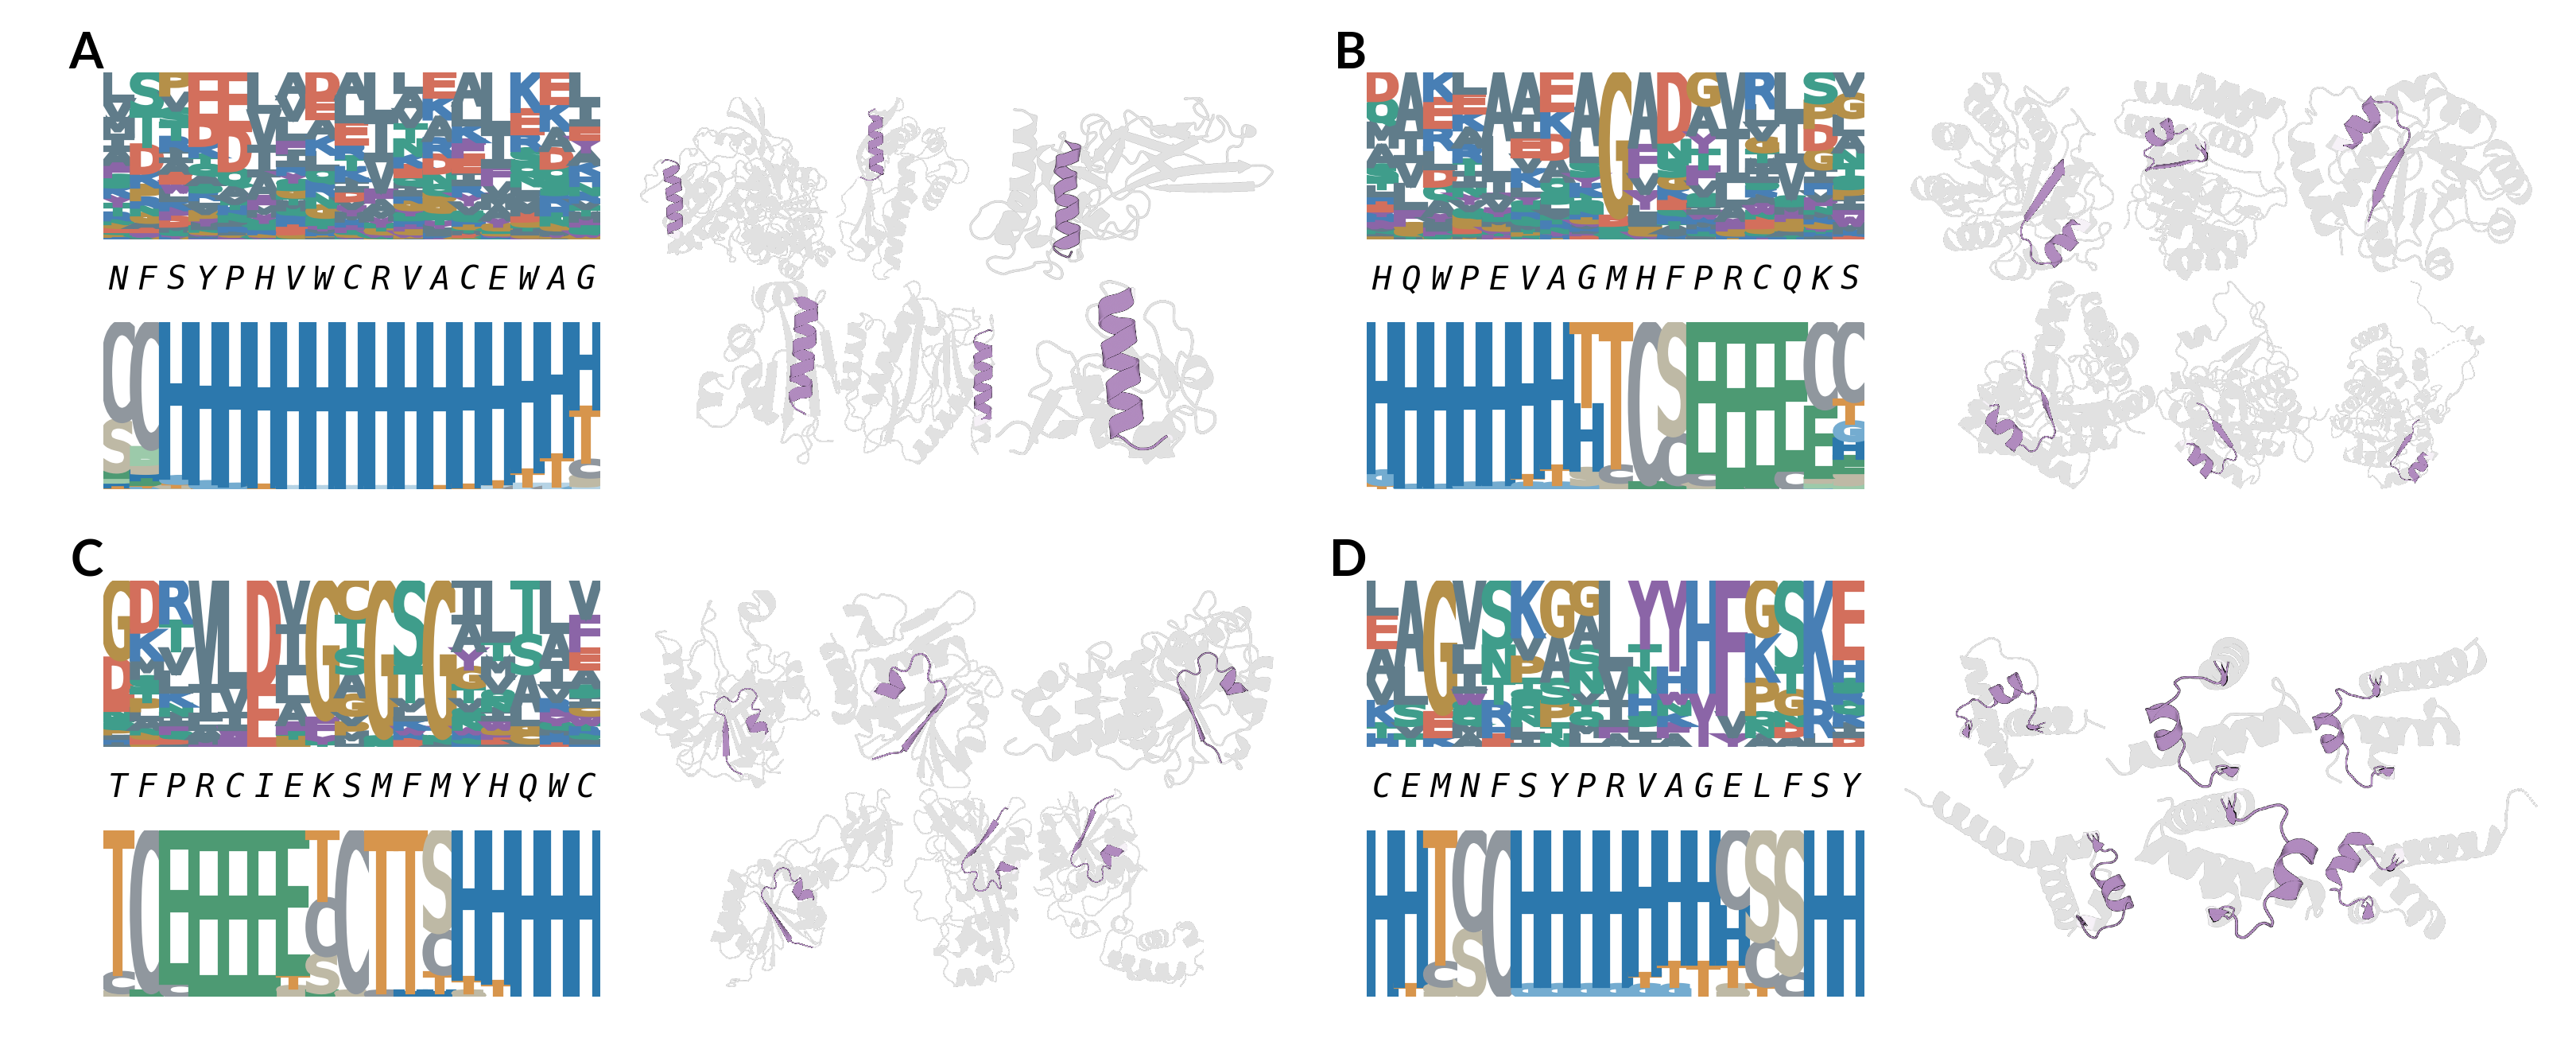

In [12]:
def make_panel(container, panel):
    motif_row = selected.loc[selected['panel'].eq(panel)].iloc[0]
    motif = motif_row['motif']
    panel_profiles = profiles.loc[profiles['panel'].eq(panel)]
    panel_representatives = representatives.loc[
        representatives['panel'].eq(panel)
    ].sort_values('display_order')

    grid = container.get_subplotspec().subgridspec(
        3, 2, height_ratios=[1, 0.5, 1], hspace=0, wspace=0.07, width_ratios=[.88,1.12],
    )
    aa_axis = container.figure.add_subplot(grid[0, 0])
    motif_axis = container.figure.add_subplot(grid[1, 0])
    dssp_axis = container.figure.add_subplot(grid[2, 0])
    structure_axis = container.figure.add_subplot(grid[:, 1])
    container.set_axis_off()

    plot_frequency_logo(
        aa_axis,
        panel_profiles.loc[panel_profiles['alphabet'].eq('aa')],
        AA_SYMBOLS,
        AA_COLORS,
    )
    plot_frequency_logo(
        dssp_axis,
        panel_profiles.loc[panel_profiles['alphabet'].eq('dssp')],
        DSSP_SYMBOLS,
        DSSP_COLORS,
    )

    motif_axis.set_xlim(0, len(motif))
    motif_axis.set_ylim(0, 1)
    motif_axis.set_axis_off()
    for index, character in enumerate(motif):
        motif_axis.text(
            index + 0.5, 0.5, character,
            ha='center', va='center',
            fontsize=STYLE['motif_size'],
            fontweight=STYLE['motif_weight'],
            fontstyle='italic',
            fontfamily=STYLE['logo_font_family'],
        )

    render_paths = [ASSETS / f'{name}_pymol.png'
                    for name in panel_representatives.sequence_id]
    structure_axis.imshow(structure_grid(render_paths), interpolation='nearest')
    structure_axis.set_axis_off()

figure, containers = plt.subplots(
    2, 2,
    figsize=STYLE['figure_size'],
    gridspec_kw={'hspace': STYLE['hspace'], 'wspace': STYLE['wspace']},
)
figure.subplots_adjust(left=.04,right=.985,bottom=.04,top=.93)
for panel, container in zip('ABCD', containers.ravel()):
    make_panel(container, panel)
    container.text(
        0, 1.1, panel,
        transform=container.transAxes,
        fontsize=STYLE['panel_label_size'],
        fontweight='bold', va='top', ha='right',
        fontfamily=STYLE['font_family'],
    )

with BytesIO() as image_buffer:
    figure.savefig(image_buffer, format='png', dpi=STYLE['dpi'], facecolor='white')
    plt.close(figure)
    display(InlineImage(data=image_buffer.getvalue()))

## Scop superfamily fold

In [13]:
plt.close('all')
plt.rcdefaults()



ROOT = Path('..').resolve()
DATA = ROOT / 'data'
mpl.rcParams.update({
    'font.family':'Lato', 'font.size':7, 'axes.labelsize':7,
    'xtick.labelsize':6.5, 'ytick.labelsize':6.5,
    'axes.spines.top':False, 'axes.spines.right':False,
    'axes.linewidth':.65, 'xtick.major.size':2.5, 'ytick.major.size':2.5,
    'grid.color':'#dedde1', 'grid.linewidth':.45,
    'path.simplify':False, 'legend.frameon':False,
})
RAW = DATA/'plot_tables/scop/alphabet/raw_score'
SEARCH = DATA/'plot_tables/scop/search'
CURRENT = DATA/'plot_tables/steam_current/scop'
alphabet = pd.read_csv(RAW/'curves.tsv', sep='\t')

def superfamily_rows(path, excluded=()):
    # Read the search table once and select the panels used here.
    chunks = []
    for chunk in pd.read_csv(path, sep='\t', chunksize=250000):
        keep = (chunk.hierarchy.eq('superfamily') &
                chunk.metric.isin(['sensitivity','weighted_pr']) &
                ~chunk.method.isin(excluded))
        chunks.append(chunk.loc[keep])
    result = pd.concat(chunks, ignore_index=True)
    return result

search = superfamily_rows(SEARCH/'curves.tsv', excluded=('steam','eba'))
current = superfamily_rows(CURRENT/'curves.tsv')
domain_metrics = json.loads((DATA/'plot_tables/scop/alphabet/domain_only/metrics.json').read_text())

def xy(frame):
    if 'point_index' in frame:
        frame = frame.sort_values('point_index')
    if 'recall' in frame:
        return frame.recall.to_numpy(float), frame.weighted_precision.to_numpy(float)
    return frame.x.to_numpy(float), frame.y.to_numpy(float)

def alphabet_curve(method, level, metric):
    if level == 'fold':
        suffix = 'fold_sensitivity' if metric == 'sensitivity' else 'fold_curve'
        return xy(pd.read_csv(RAW/f'{method}_{suffix}.tsv', sep='\t'))
    if method == 'tea_domain':
        if metric == 'weighted_pr':
            return xy(pd.read_csv(RAW/'tea_domain_superfamily_curve.tsv', sep='\t'))
        values = [row['sensitivity'] for row in domain_metrics['levels'][level]['per_query'].values()
                  if row.get('sensitivity') is not None]
        values = np.asarray(values, dtype=float)
        values = np.sort(values[np.isfinite(values)])[::-1]
        return np.arange(len(values)+1)/len(values), np.r_[values,0.]
    return xy(alphabet.loc[alphabet.method.eq(method) & alphabet.hierarchy.eq(level) & alphabet.metric.eq(metric)])

def search_curve(method, level, metric):
    if method == 'prostt5_foldseek_full_chain':
        frame = pd.read_csv(SEARCH/'prostt5_full_chain/curves.tsv',sep='	')
        return xy(frame.loc[frame.hierarchy.eq(level)&frame.metric.eq(metric)])
    if level == 'fold':
        base = CURRENT if method in ('steam','steam_domain') else SEARCH
        return xy(pd.read_csv(base/'fold'/method/f'{metric}.tsv', sep='\t'))
    if method == 'eba':
        return xy(pd.read_csv(SEARCH/'domain_only'/f'eba_superfamily_{metric}.tsv', sep='\t'))
    frame = current if method in ('steam','steam_domain') else search
    return xy(frame.loc[frame.method.eq(method) & frame.metric.eq(metric)])


# Rows: superfamily, fold. Left pair: alphabet; right pair: search.
ALPHABET = [
    ('tea_full','TEA','#654183','o','-'),
    ('tea_domain','TEA (domain)','#9672b2','D',(0,(4,1.7))),
    ('aa','AA','#3E88B7','P',(0,(5,2.5))),
    ('structural_3di','Structural 3Di','#d84b48','X',(0,(3.2,1.5,1,1.5))),
    ('prostt5_3di','ProstT5 3Di (domain)','#c68d45','v',(0,(2.3,1.4))),
    ('prostt5_3di_full_chain','ProstT5 3Di','#df951e','^','-'),
]
SEARCH_METHODS = [
    ('steam','STEAM','#654183','o','-'),
    ('steam_domain','STEAM (domain)','#9672b2','h',(0,(4,1.7))),
    ('mmseqs2','MMseqs2','#3E88B7','P',(0,(5,2.5))),
    ('prostt5_foldseek','ProstT5–Foldseek (domain)','#c68d45','v',(0,(2.3,1.4))),
    ('prostt5_foldseek_full_chain','ProstT5–Foldseek','#df951e','^','-'),
    ('foldseek','Foldseek','#d84b48','X',(0,(3.2,1.5,1,1.5))),
    ('reseek','Reseek','#27756E','D',(0,(5,1.5,1,1.5))),
    ('eba','EBA (domain)','#ae86c2','s',(0,(.8,3))),
    ('dali','DALI','#687589','v',(0,(.8,1.8))),
]

### Sensitivity and precision–recall curves

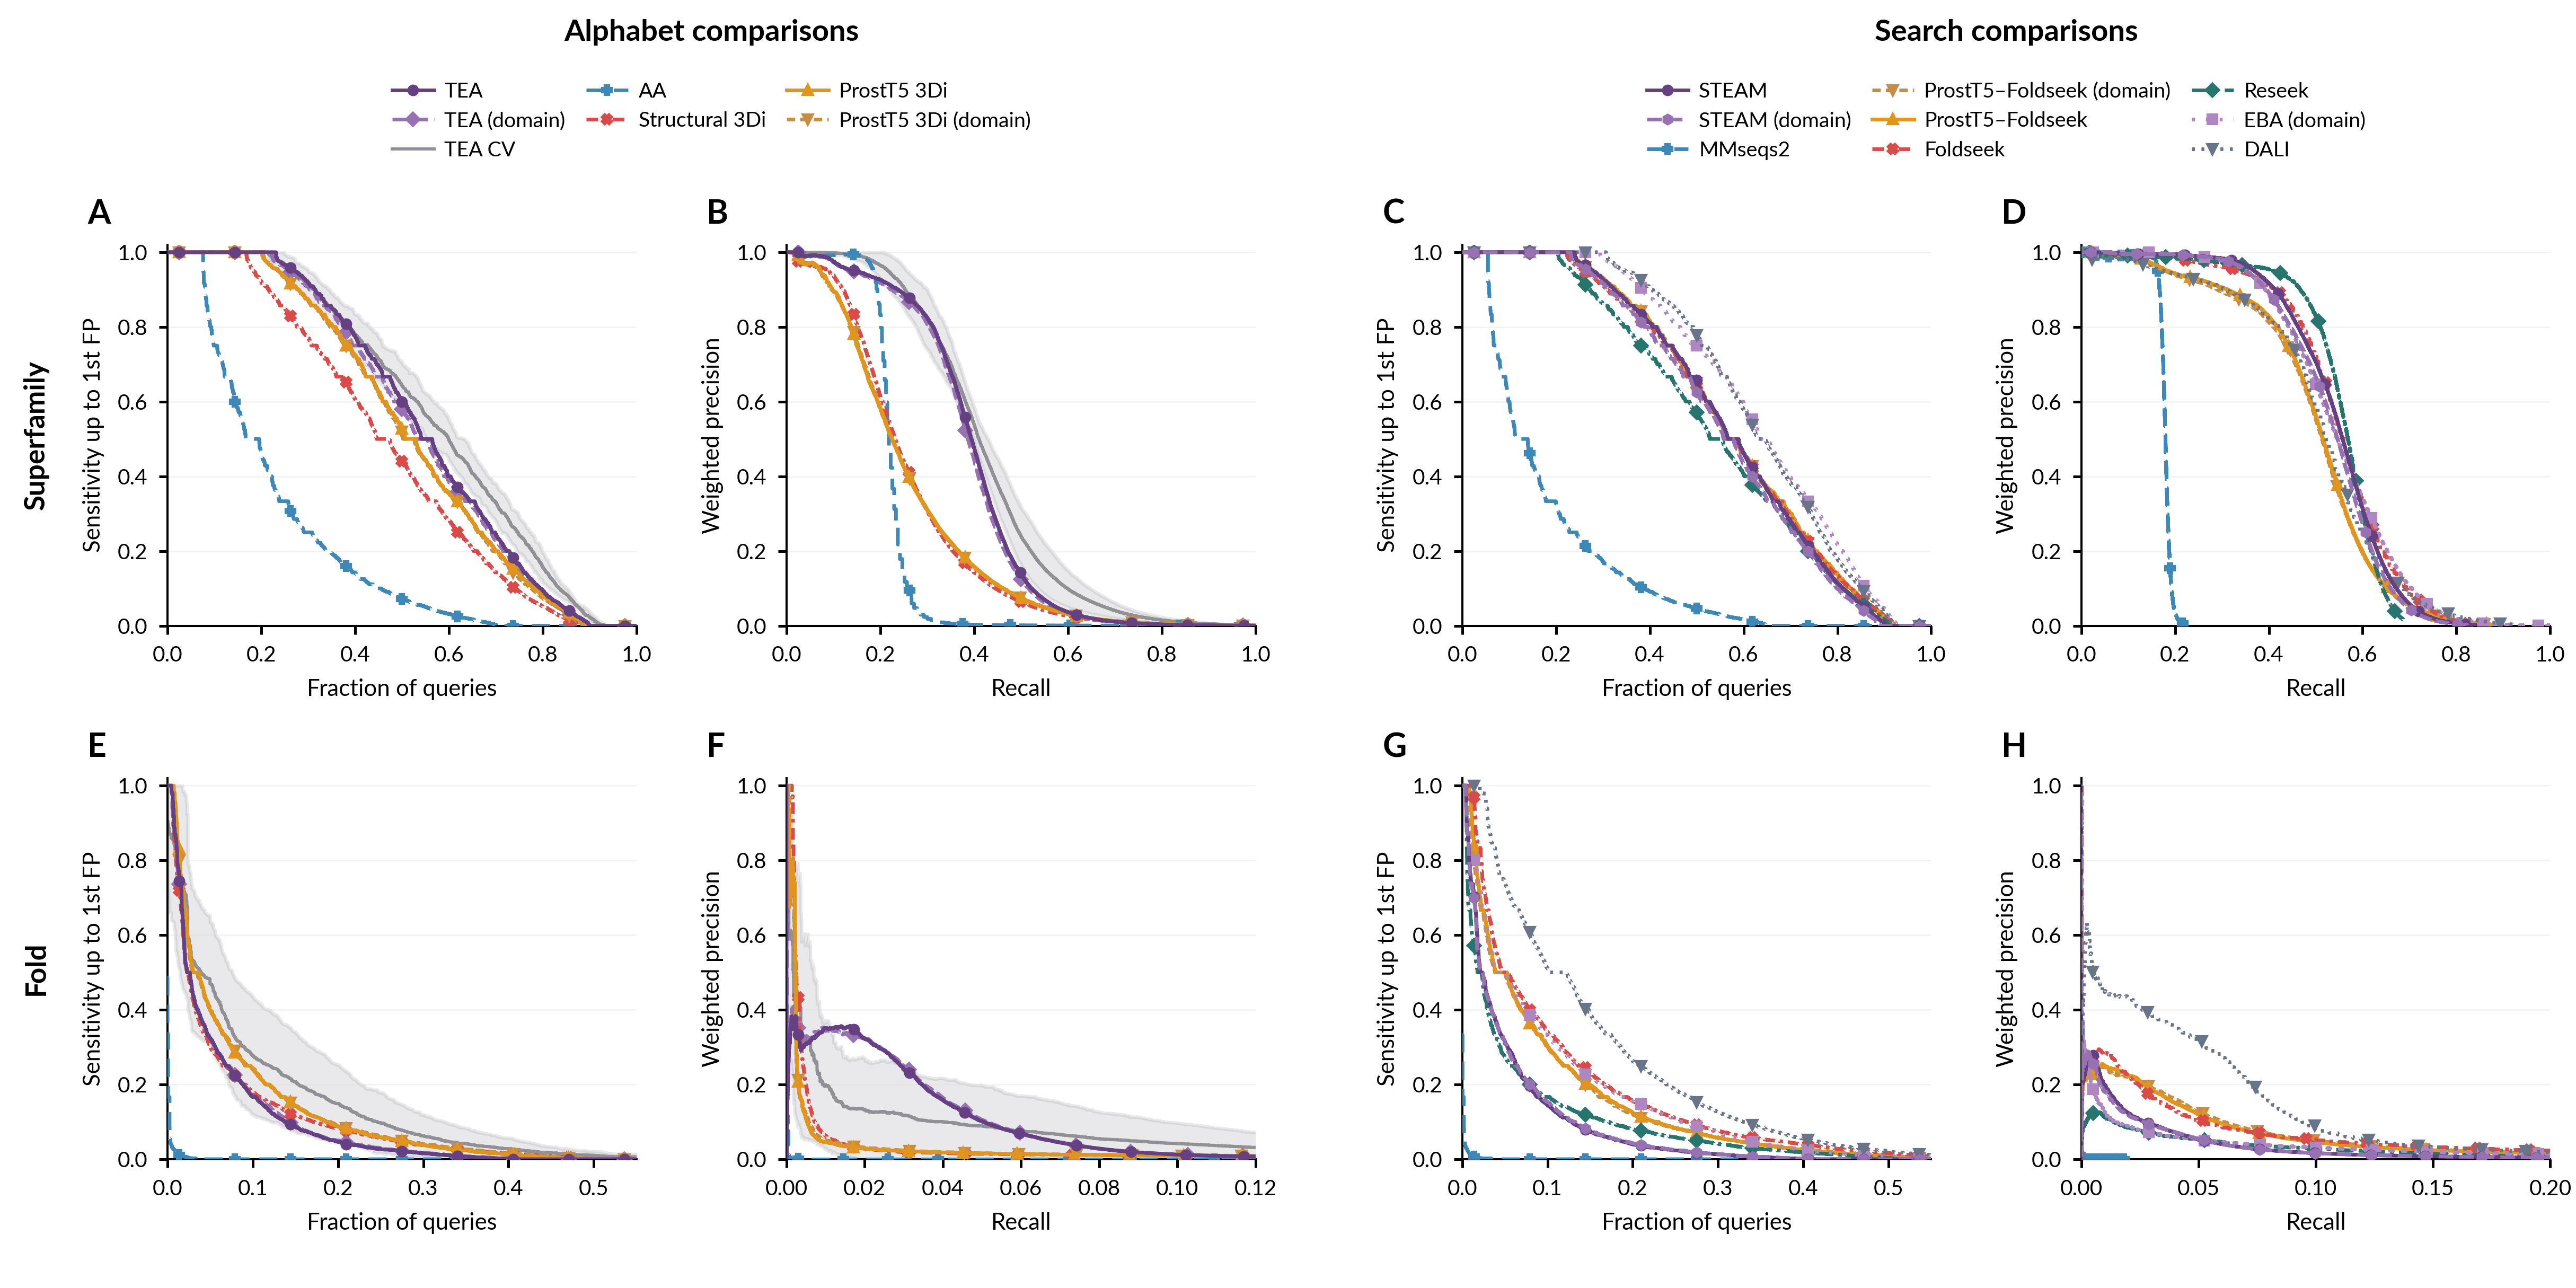

In [14]:
def draw_curve(axis, x, y, label, color, marker, dash, where, zorder=3):
    line = axis.step(x,y,where=where,label=label,color=color,linestyle=dash,
                     linewidth=1.1, zorder=zorder)[0]
    line.get_path().should_simplify = False
    # Space the markers and retain every vertex in the empirical curve.
    left,right = axis.get_xlim()
    lo,hi = max(left,float(x.min())),min(right,float(x.max()))
    ordered = x[::-1] if x[0] > x[-1] else x
    positions = np.linspace(lo+.025*(hi-lo),hi-.025*(hi-lo),9)
    indices = np.clip(np.searchsorted(ordered,positions,side='right')-1,0,len(x)-1)
    indices = np.unique(len(x)-1-indices if x[0] > x[-1] else indices)
    line.set_marker(marker)
    line.set_markersize(2.5)
    line.set_markevery(indices)

def draw_cv(axis, level, metric):
    folds = [alphabet_curve(f'tea_cv_outer{i}',level,metric) for i in range(4)]
    folds = [(x[::-1],y[::-1]) if x[0] > x[-1] else (x,y) for x,y in folds]
    grid = np.unique(np.concatenate([x for x,_ in folds]))
    grid = grid[(grid >= max(x[0] for x,_ in folds)) & (grid <= min(x[-1] for x,_ in folds))]
    values = []
    for x,y in folds:
        indices = (np.searchsorted(x,grid,side='left') if metric == 'weighted_pr'
                   else np.searchsorted(x,grid,side='right')-1)
        values.append(y[np.clip(indices,0,len(y)-1)])
    values = np.asarray(values)
    mean = values.mean(axis=0)
    half = 1.96*values.std(axis=0,ddof=0)/np.sqrt(4)
    step = 'pre' if metric == 'weighted_pr' else 'post'
    axis.fill_between(grid,np.clip(mean-half,0,1),np.clip(mean+half,0,1),
                      step=step,color='#929097',alpha=.20,zorder=1)
    axis.step(grid,mean,where=step,label='TEA CV',color='#929097',linewidth=.95,zorder=2)

fig = plt.figure(figsize=(10.8,5.4),facecolor='white')
outer = fig.add_gridspec(1,2,left=.065,right=.99,bottom=.10,top=.81,wspace=.19)
axes = np.empty((2,4),dtype=object)
for group in range(2):
    grid = outer[group].subgridspec(2,2,hspace=.40,wspace=.32)
    for row in range(2):
        for column in range(2):
            axes[row,group*2+column] = fig.add_subplot(grid[row,column])

for row,level in enumerate(('superfamily','fold')):
    for column in range(4):
        axis = axes[row,column]
        metric = 'sensitivity' if column%2 == 0 else 'weighted_pr'
        axis.set(xlim=(0,.55 if row == 1 and metric == 'sensitivity' else
                          .12 if row == 1 and column == 1 else
                          .20 if row == 1 and column == 3 else 1), ylim=(0,1.02))
        if column < 2:
            draw_cv(axis,level,metric)
            methods,loader = ALPHABET,alphabet_curve
        else:
            methods,loader = SEARCH_METHODS,search_curve
        for method,label,color,marker,dash in methods:
            x,y = loader(method,level,metric)
            where = 'pre' if row == 1 and column == 1 else 'post'
            draw_curve(axis,x,y,label,color,marker,dash,where,
                       zorder=5 if method in ('tea_full','steam','steam_domain') else 3)
        axis.set_xlabel('Fraction of queries' if metric == 'sensitivity' else 'Recall')
        axis.set_ylabel('Sensitivity up to 1st FP' if metric == 'sensitivity' else 'Weighted precision')
        axis.grid(axis='y',alpha=.35)
        axis.text(-.17,1.04,chr(ord('A')+row*4+column),transform=axis.transAxes,
                  fontsize=10,fontweight='bold',va='bottom')
    bounds = axes[row,0].get_position()
    fig.text(.009,(bounds.y0+bounds.y1)/2,level.capitalize(),rotation=90,
             va='center',ha='left',fontsize=8.5,fontweight='bold')

for group,title,ncol in ((0,'Alphabet comparisons',3),(1,'Search comparisons',3)):
    left,right = axes[0,group*2].get_position().x0,axes[0,group*2+1].get_position().x1
    center = (left+right)/2
    fig.text(center,.985,title,ha='center',va='top',fontsize=9,fontweight='bold')
    handles,labels = axes[0,group*2].get_legend_handles_labels()
    if group == 0:
        order = ['TEA','TEA (domain)','TEA CV','AA','Structural 3Di','ProstT5 3Di','ProstT5 3Di (domain)']
        lookup = dict(zip(labels,handles))
        handles,labels = [lookup[label] for label in order],order
    fig.legend(handles,labels,loc='upper center',bbox_to_anchor=(center,.951),
               fontsize=6.3,ncol=ncol,columnspacing=1.0,handlelength=2,
               handletextpad=.5,labelspacing=.5)

with BytesIO() as image_buffer:
    fig.savefig(image_buffer, format='png', dpi=450,facecolor='white')
    plt.close(fig)
    display(InlineImage(data=image_buffer.getvalue()))
print(path)

## Tea matrices

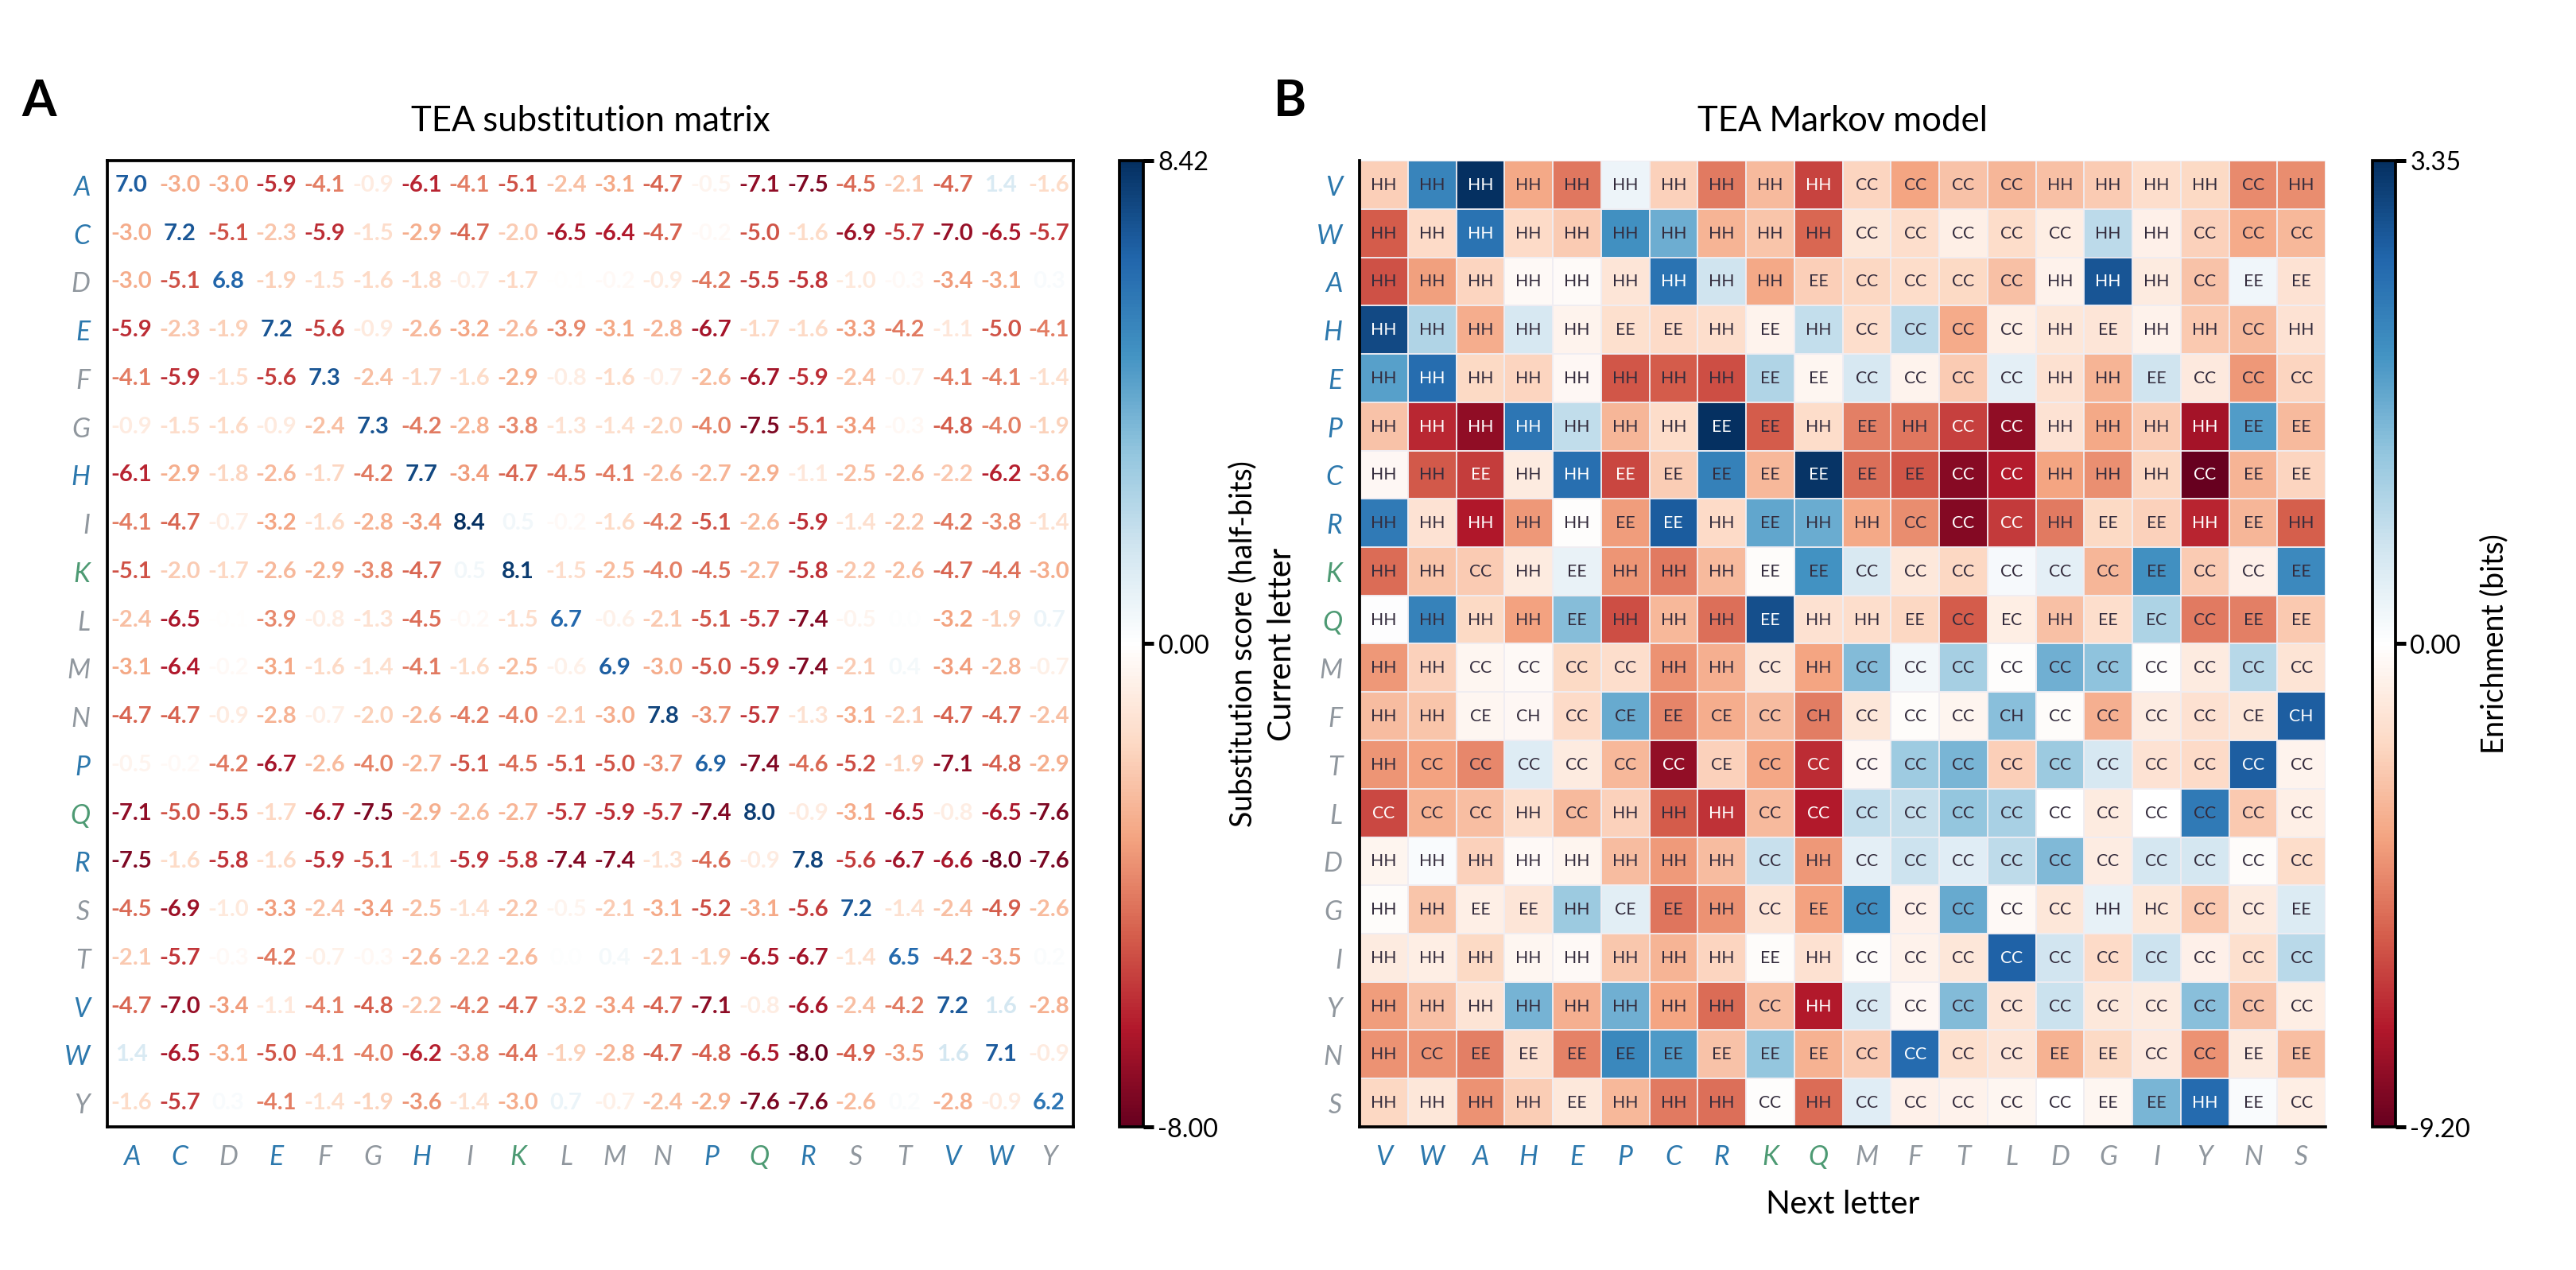

In [15]:
plt.close('all')
plt.rcdefaults()


from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm

ROOT=Path('..').resolve()
configuration=json.loads((ROOT/'data/search_results/steam_final/current/calibrated_configuration.json').read_text())
source=ROOT/configuration['score']['matrix']
rows=[line.split() for line in source.read_text().splitlines() if line.strip() and not line.startswith('#')]
header=rows[0]
native={row[0]:np.array(row[1:],dtype=float) for row in rows[1:]}
letters=list('ACDEFGHIKLMNPQRSTVWY')
scores=np.array([[native[a][header.index(b)] for b in letters] for a in letters])
np.testing.assert_allclose(scores,scores.T,atol=1e-12)
model=json.loads((ROOT/'data/plot_tables/markov_model_gallery/sse_comparison/models.json').read_text())['steam_tea']
preference=np.asarray(model['SSE_given_letter']).argmax(1)
letter_colors=['#2C78AD','#4D9A73','#90979E']
norm=TwoSlopeNorm(vmin=float(scores.min()),vcenter=0,vmax=float(scores.max()))
cmap=LinearSegmentedColormap.from_list('red_white_blue',['#67001f','#b2182b','#d6604d','#f4a582','#fddbc7','#ffffff','#d1e5f0','#92c5de','#4393c3','#2166ac','#053061'],N=257)
np.testing.assert_allclose(cmap(norm(0)),[1,1,1,1])

MARKOV=ROOT/'data/plot_tables/markov_model_gallery/sse_comparison'

model=json.loads((MARKOV/'models.json').read_text())['steam_tea']
native=ROOT/'data/search_results/steam_final/parameters/seed_markov.txt'
native_lines=native.read_text().splitlines()
letters=np.array(list(model['alphabet']))
indices=[native_lines[1].index(letter) for letter in letters]
pi=np.asarray(model['marginal']);transition=np.asarray(model['transition'])
native_transition=np.array([np.fromstring(line,sep=' ') for line in native_lines[4:24]])
np.testing.assert_allclose(transition,native_transition[np.ix_(indices,indices)])
np.testing.assert_allclose(transition.sum(1),1)
observed=np.load(MARKOV/'observed_counts.npz')['steam_tea_SSE_pairs']

def axes(fig,rectangle):
    width,height=fig.get_size_inches()
    x,y,w,h=rectangle
    return fig.add_axes([x/width,y/height,w/width,h/height])


matrix_path=ROOT/'data/checkpoints/public_export/matrix.json'
matrix=json.loads(matrix_path.read_text())
matrix_order=[matrix['alphabet'].index(letter) for letter in letters]
joint=np.asarray(matrix['joint'])[np.ix_(matrix_order,matrix_order)]
background=np.asarray(matrix['background'])[matrix_order]
np.testing.assert_allclose(scores,2*np.log2(joint/(background[:,None]*background[None,:])),atol=1e-10)

mpl.rcParams.update({'font.family':'Lato','font.size':6.5,'savefig.bbox':None,
    'axes.linewidth':.6,'axes.spines.top':False,'axes.spines.right':False,
    'xtick.major.size':0,'ytick.major.size':0,'xtick.labelsize':5.4,'ytick.labelsize':5.4})
fig=plt.figure(figsize=(7.2,3.55),dpi=150)
width,height=fig.get_size_inches()
rectangles=[(.30,.40,2.70,2.70),(3.80,.40,2.70,2.70)]
matrix_axes=[axes(fig,rectangle) for rectangle in rectangles]
mixture=np.asarray(model['SSE_given_letter']);preference=mixture.argmax(1)
order=np.array(sorted(range(20),key=lambda i:(preference[i],-mixture[i].max())))
ss_colors=['#2C78AD','#4D9A73','#90979E']
enrichment=np.log2(transition/pi[None,:])
markov_norm=TwoSlopeNorm(vmin=float(enrichment.min()),vcenter=0,vmax=float(enrichment.max()))
score_norm=TwoSlopeNorm(vmin=float(scores.min()),vcenter=0,vmax=float(scores.max()))
totals=observed.sum(0);dominant=observed.argmax(0)
for k,(ax,values,title) in enumerate(zip(matrix_axes,[scores,enrichment],
        ['TEA substitution matrix','TEA Markov model'])):
    display_order=np.arange(20) if k==0 else order
    norm=score_norm if k==0 else markov_norm
    ax.set(xlim=(-.5,19.5),ylim=(19.5,-.5),xticks=range(20),yticks=range(20),
        xticklabels=letters[display_order],yticklabels=letters[display_order])
    ax.set_aspect('equal',adjustable='box')
    ax.set_title(title,fontsize=7,pad=6)
    for labels in [ax.get_xticklabels(),ax.get_yticklabels()]:
        for text,index in zip(labels,display_order):
            text.set_fontstyle('italic');text.set_color(ss_colors[preference[index]])
    if k==0:
        for row,i in enumerate(display_order):
            for col,j in enumerate(display_order):
                value=values[i,j];text=f'{value:.1f}'
                if text=='-0.0':text='0.0'
                ax.text(col,row,text,ha='center',va='center',fontsize=4.7,
                        weight='bold',color=cmap(norm(value)))
        for spine in ax.spines.values():spine.set_visible(True)
        image=mpl.cm.ScalarMappable(norm=norm,cmap=cmap)
    else:
        image=ax.imshow(values[np.ix_(display_order,display_order)],cmap=cmap,norm=norm,
                        interpolation='nearest')
        ax.set(xlabel='Next letter',ylabel='Current letter')
        ax.set_xticks(np.arange(21)-.5,minor=True);ax.set_yticks(np.arange(21)-.5,minor=True)
        ax.grid(which='minor',color='#f0edf2',linewidth=.3);ax.tick_params(which='minor',length=0)
        for row,i in enumerate(display_order):
            for col,j in enumerate(display_order):
                if not totals[i,j]:continue
                index=int(dominant[i,j]);text='HEC'[index//3]+'HEC'[index%3]
                rgb=np.asarray(cmap(norm(values[i,j]))[:3])
                linear=np.where(rgb<=.04045,rgb/12.92,((rgb+.055)/1.055)**2.4)
                ax.text(col,row,text,ha='center',va='center',fontsize=3.4,
                    color='white' if linear@np.array([.2126,.7152,.0722])<.179 else '#332b3c')
    x0,y0,w,h=rectangles[k]
    cb=fig.colorbar(image,cax=axes(fig,(x0+w+.13,y0,.065,h)),
                   ticks=[norm.vmin,0,norm.vmax],format='%.2f')
    cb.ax.tick_params(labelsize=5.2,length=2,pad=1)
    cb.set_label('Substitution score (half-bits)' if k==0 else 'Enrichment (bits)',
                 fontsize=6,labelpad=2)
    fig.text((x0-.24)/width,(y0+h+.10)/height,'ABC'[k],fontsize=10,weight='bold',va='bottom')
print('Validated the current simple substitution matrix and frozen STEAM Markov model',flush=True)
with BytesIO() as image_buffer:
    fig.savefig(image_buffer, format='png', dpi=450,facecolor='white')
    plt.close(fig)
    display(InlineImage(data=image_buffer.getvalue()))